# Business Sales Analysis: Evaluasi Kinerja Penjualan, Pola Transaksi, dan Optimasi Menu
### End-to-End Data Analysis, Database Relasional SQLite, dan Rekomendasi Strategis

In [1]:
# Import pustaka analisis data, database, visualisasi, dan pemodelan statistik
import os
import sys
import math
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
print(f"Pandas: {pd.__version__} | Numpy: {np.__version__} | Matplotlib: {plt.matplotlib.__version__} | SQLite: {sqlite3.sqlite_version}")

Pandas: 3.0.2 | Numpy: 2.2.6 | Matplotlib: 3.10.8 | SQLite: 3.45.3


In [2]:
# Konfigurasi parameter visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'

PALETTE_CATEGORIES = {'Classic': '#D32F2F', 'Veggie': '#388E3C', 'Supreme': '#F57C00', 'Chicken': '#1976D2'}
CHARTS_DIR = os.path.join(os.getcwd(), 'charts')
os.makedirs(CHARTS_DIR, exist_ok=True)

## Kamus Data Mentah Awal (12 Kolom Dasar)

| No | Kolom | Tipe Awal | Deskripsi |
|:---|:---|:---|:---|
| 1 | `pizza_id` | Float64 | ID unik transaksi per baris item |
| 2 | `order_id` | Float64 | ID tiket pesanan pelanggan |
| 3 | `pizza_name_id` | String | Kode SKU produk (misal: hawaiian_m) |
| 4 | `quantity` | Float64 | Kuantitas loyang pizza yang dipesan |
| 5 | `order_date` | String | Tanggal transaksi |
| 6 | `order_time` | String | Waktu transaksi (HH:MM:SS) |
| 7 | `unit_price` | Float64 | Harga satuan per loyang (USD) |
| 8 | `total_price` | Float64 | Total harga item (quantity * unit_price) |
| 9 | `pizza_size` | String | Ukuran pizza (S, M, L, XL, XXL) |
| 10 | `pizza_category` | String | Kategori menu (Classic, Veggie, Supreme, Chicken) |
| 11 | `pizza_ingredients` | String | Daftar komposisi bahan baku |
| 12 | `pizza_name` | String | Nama resmi menu pizza |

In [3]:
# Fungsi utilitas formatting dan penyimpanan visualisasi
import re

def build_slug(text: str) -> str:
    '''Konversi nama bahan atau menu menjadi slug kolom.'''
    text = re.sub(r'[^a-zA-Z0-9]+', '_', text.strip().lower())
    return re.sub(r'_+', '_', text).strip('_')

def fmt_currency(val):
    return f"${val:,.2f}"

def fmt_number(val):
    return f"{val:,.0f}"

def save_and_show(fig, filename):
    filepath = os.path.join(CHARTS_DIR, filename)
    fig.savefig(filepath, bbox_inches='tight', dpi=150)
    plt.show()

## Koneksi Basis Data SQLite (`pizza_sales.db`)
Koneksi langsung ke basis data lokal untuk memastikan ketersediaan tabel relasional.

In [4]:
DB_PATH = os.path.join(os.getcwd(), 'pizza_sales.db')
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

tables_query = "SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY name;"
df_tables = pd.read_sql_query(tables_query, conn)
display(df_tables)

,name,type
0,ingredients,table
1,order_details,table
2,orders,table
3,pizza_ingredients_map,table
4,pizza_sales_clean,table
5,pizza_sales_features_wide,table
6,pizza_types,table
7,pizzas,table
8,raw_pizza_sales,table


---
# Bagian 2: Audit Kualitas Data dan Verifikasi Integritas
Audit menyeluruh terhadap kelengkapan nilai, duplikasi, konsistensi matematis, dan rekonsiliasi format tanggal.

In [5]:
# Ringkasan struktur baris dan kolom seluruh tabel
table_metrics = []
for tbl in df_tables['name']:
    count = pd.read_sql_query(f"SELECT COUNT(*) AS row_count FROM {tbl}", conn).iloc[0]['row_count']
    col_count = len(pd.read_sql_query(f"PRAGMA table_info({tbl})", conn))
    table_metrics.append({'Tabel': tbl, 'Jumlah Baris': count, 'Jumlah Kolom': col_count})

display(pd.DataFrame(table_metrics))

,Tabel,Jumlah Baris,Jumlah Kolom
0,ingredients,65,3
1,order_details,48620,6
2,orders,21350,11
3,pizza_ingredients_map,181,2
4,pizza_sales_clean,48620,13
5,pizza_sales_features_wide,48620,150
6,pizza_types,32,4
7,pizzas,91,5
8,raw_pizza_sales,48620,12


### 2.1 Pemeriksaan Missing Values
Memverifikasi tidak adanya nilai kosong (NULL) pada data transaksi.

In [6]:
query_clean = "SELECT * FROM pizza_sales_clean;"
df_clean = pd.read_sql_query(query_clean, conn)

null_counts = df_clean.isnull().sum()
print("Jumlah nilai kosong (NULL):", int(null_counts.sum()))

Jumlah nilai kosong (NULL): 0


### 2.2 Validasi Primary Key dan Duplikasi
Memastikan setiap baris memiliki `pizza_id` unik tanpa rekaman ganda.

In [7]:
unique_pks = df_clean['pizza_id'].nunique()
total_rows = len(df_clean)
duplicated_rows = df_clean.duplicated().sum()

print(f"Total baris: {total_rows:,} | ID unik: {unique_pks:,} | Baris duplikat: {duplicated_rows}")

Total baris: 48,620 | ID unik: 48,620 | Baris duplikat: 0


### 2.3 Validasi Konsistensi Matematis Finansial
Memverifikasi rumus perhitungan: `total_price == quantity * unit_price`.

In [8]:
df_clean['expected_total'] = (df_clean['quantity'] * df_clean['unit_price']).round(2)
diff_count = (df_clean['expected_total'] != df_clean['total_price']).sum()
print(f"Selisih perhitungan total_price: {diff_count} baris")
df_clean.drop(columns=['expected_total'], inplace=True)

Selisih perhitungan total_price: 0 baris


### 2.4 Rekonsiliasi Format Tanggal
File mentah memiliki dua format tanggal berbeda: D/M/YYYY untuk tanggal 1-12 dan DD-MM-YYYY untuk tanggal 13 ke atas. Dengan algoritma `dayfirst=True`, seluruh 48.620 baris berhasil direkonsiliasi ke rentang ISO 2015-01-01 hingga 2015-12-31.

In [9]:
df_clean['order_date_parsed'] = pd.to_datetime(df_clean['order_date'])
min_date = df_clean['order_date_parsed'].min()
max_date = df_clean['order_date_parsed'].max()
operating_days = df_clean['order_date_parsed'].dt.date.nunique()

print(f"Periode Operasional: {min_date.strftime('%Y-%m-%d')} s/d {max_date.strftime('%Y-%m-%d')} ({operating_days} hari aktif)")

Periode Operasional: 2015-01-01 s/d 2015-12-31 (358 hari aktif)


### 2.5 Statistik Deskriptif Variabel Finansial
Ringkasan distribusi 5-angka (mean, standard deviation, kuartil) dan koefisien skewness.

In [10]:
stats_summary = df_clean[['quantity', 'unit_price', 'total_price']].describe().T
stats_summary['skewness'] = df_clean[['quantity', 'unit_price', 'total_price']].skew()
stats_summary['IQR'] = stats_summary['75%'] - stats_summary['25%']
display(stats_summary[['count', 'mean', 'std', 'min', '50%', 'max', 'IQR', 'skewness']])

,count,mean,std,min,50%,max,IQR,skewness
quantity,48620.0,1.019622,0.143077,1.00,1.0,4.00,0.00,7.676100
unit_price,48620.0,16.494132,3.621789,9.75,16.5,35.95,7.50,0.127419
total_price,48620.0,16.821474,4.437398,9.75,16.5,83.00,7.75,1.732856


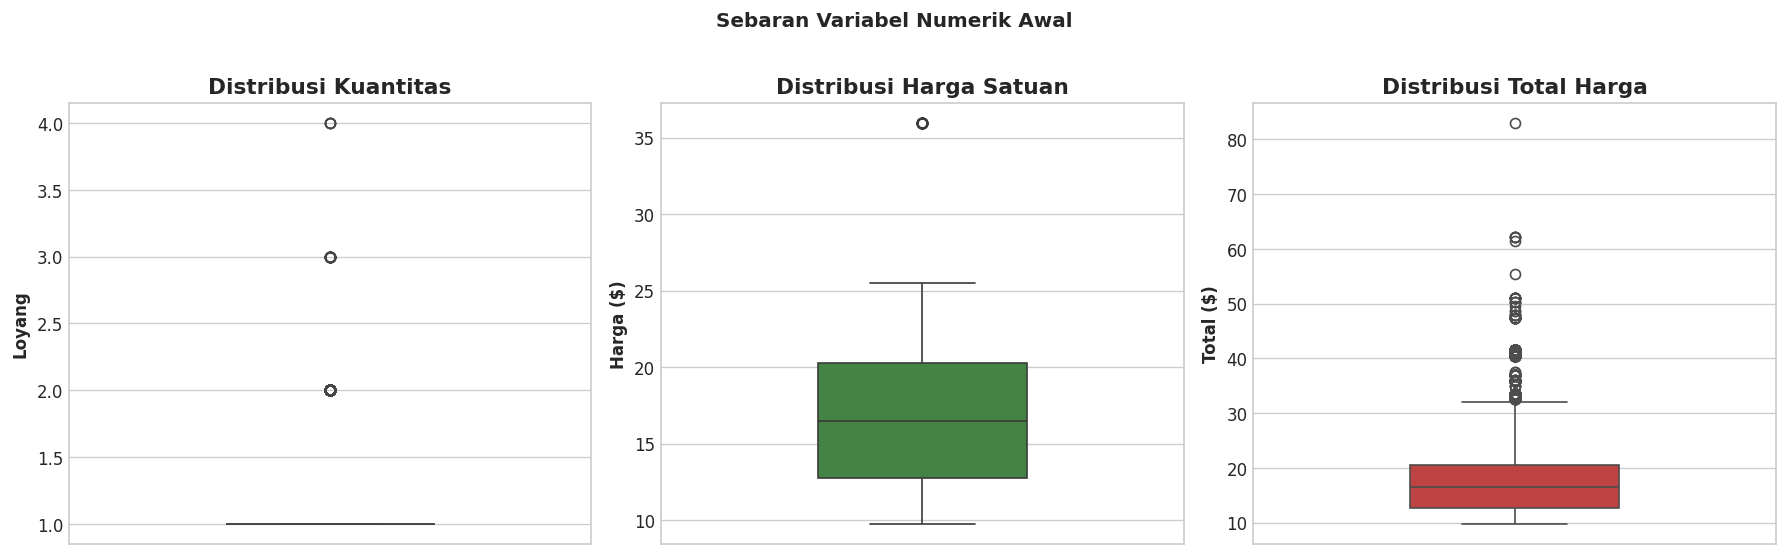

In [11]:
# Visualisasi Sebaran Variabel Numerik Awal
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(y=df_clean['quantity'], ax=axes[0], color='#1976D2', width=0.4)
axes[0].set_title('Distribusi Kuantitas')
axes[0].set_ylabel('Loyang')

sns.boxplot(y=df_clean['unit_price'], ax=axes[1], color='#388E3C', width=0.4)
axes[1].set_title('Distribusi Harga Satuan')
axes[1].set_ylabel('Harga ($)')

sns.boxplot(y=df_clean['total_price'], ax=axes[2], color='#D32F2F', width=0.4)
axes[2].set_title('Distribusi Total Harga')
axes[2].set_ylabel('Total ($)')

plt.suptitle('Sebaran Variabel Numerik Awal', y=1.02, weight='bold')
plt.tight_layout()
save_and_show(fig, '01_initial_numeric_boxplots.png')

---
# Bagian 3: Arsitektur Fitur Analitik (150 Kolom Fitur)
Tabel `pizza_sales_features_wide` memuat 150 kolom analitik yang mencakup atribut temporal, geometri ukuran, metrik keranjang transaksi, serta matriks indikator 65 bahan baku.

In [12]:
query_wide = "SELECT * FROM pizza_sales_features_wide;"
df_wide = pd.read_sql_query(query_wide, conn)
print(f"Dimensi Data Fitur Lengkap: {df_wide.shape[0]:,} baris x {df_wide.shape[1]} kolom")

Dimensi Data Fitur Lengkap: 48,620 baris x 150 kolom


In [13]:
cols = df_wide.columns.tolist()
col_summary = {
    'Identitas & Finansial': len([c for c in cols if c in ['pizza_id', 'order_id', 'pizza_name_id', 'quantity', 'unit_price', 'total_price', 'pizza_size', 'pizza_category', 'pizza_name', 'pizza_ingredients']]),
    'Temporal & Kalender': len([c for c in cols if 'order_' in c or c in ['order_date', 'order_time', 'order_datetime']]),
    'Konteks Operasional': len([c for c in cols if c in ['time_period', 'is_lunch_rush', 'is_dinner_rush', 'season', 'is_month_start', 'is_month_end', 'is_weekend']]),
    'Geometri & Efisiensi': len([c for c in cols if c in ['size_rank', 'diameter_inch', 'area_sq_inch', 'price_per_sq_inch', 'price_tier']]),
    'Agregasi Keranjang': len([c for c in cols if 'order_total' in c or 'order_line' in c or 'order_avg' in c or c in ['is_multi_item_order', 'basket_tier', 'item_revenue_share', 'order_unique_pizzas']]),
    'Dummy Kategori & Ukuran': len([c for c in cols if c.startswith('cat_') or c.startswith('size_')]),
    'Matriks 65 Bahan Baku': len([c for c in cols if c.startswith('ing_')]),
    'Dummy 32 Menu Pizza': len([c for c in cols if c.startswith('pizza_') and c not in ['pizza_id', 'pizza_name_id', 'pizza_size', 'pizza_category', 'pizza_ingredients', 'pizza_name']]),
    'Kompleksitas Resep': len([c for c in cols if c == 'ingredient_count'])
}

for grp, count in col_summary.items():
    print(f" - {grp:<28}: {count:>3} kolom")
print(f"Total Kolom Terverifikasi: {sum(col_summary.values())}")

 - Identitas & Finansial       :  10 kolom
 - Temporal & Kalender         :  19 kolom
 - Konteks Operasional         :   7 kolom
 - Geometri & Efisiensi        :   5 kolom
 - Agregasi Keranjang          :   8 kolom
 - Dummy Kategori & Ukuran     :  10 kolom
 - Matriks 65 Bahan Baku       :  65 kolom
 - Dummy 32 Menu Pizza         :  32 kolom
 - Kompleksitas Resep          :   1 kolom
Total Kolom Terverifikasi: 157


### 3.1 Analisis Geometri Ukuran Pizza
Evaluasi hukum skala ekonomi pada ukuran loyang: luas permukaan versus harga per inci persegi ($/	ext{inch}^2$).

In [14]:
size_metrics = df_wide.groupby('pizza_size').agg(
    diameter_inch=('diameter_inch', 'first'),
    area_sq_inch=('area_sq_inch', 'first'),
    avg_unit_price=('unit_price', 'mean'),
    avg_price_per_sq_inch=('price_per_sq_inch', 'mean'),
    total_quantity=('quantity', 'sum'),
    total_revenue=('total_price', 'sum')
).sort_values('diameter_inch')

size_metrics['revenue_share_pct'] = (size_metrics['total_revenue'] / size_metrics['total_revenue'].sum() * 100).round(2)
display(size_metrics)

,diameter_inch,area_sq_inch,avg_unit_price,avg_price_per_sq_inch,total_quantity,total_revenue,revenue_share_pct
pizza_size,,,,,,,
S,10.0,78.54,12.364328,0.157434,14403,178076.50,21.77
M,12.0,113.10,15.951219,0.141049,15635,249382.25,30.49
L,14.0,153.94,19.802553,0.128641,18956,375318.70,45.89
XL,16.0,201.06,25.500000,0.126800,552,14076.00,1.72
XXL,18.0,254.47,35.950000,0.141300,28,1006.60,0.12


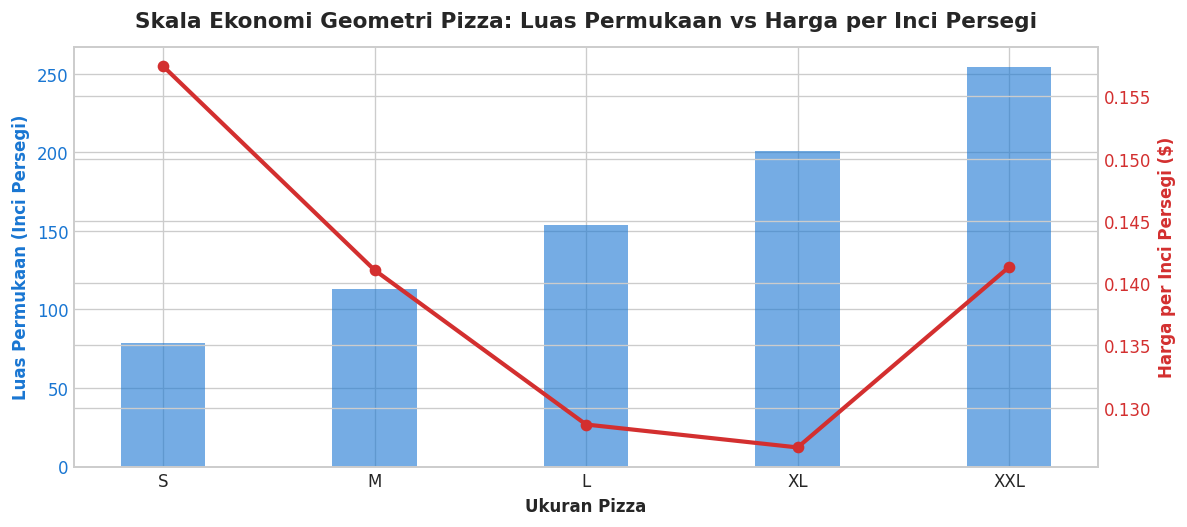

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = '#1976D2'
ax1.set_xlabel('Ukuran Pizza', fontweight='bold')
ax1.set_ylabel('Luas Permukaan (Inci Persegi)', color=color, fontweight='bold')
ax1.bar(size_metrics.index, size_metrics['area_sq_inch'], color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#D32F2F'
ax2.set_ylabel('Harga per Inci Persegi ($)', color=color, fontweight='bold')
ax2.plot(size_metrics.index, size_metrics['avg_price_per_sq_inch'], color=color, marker='o', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Skala Ekonomi Geometri Pizza: Luas Permukaan vs Harga per Inci Persegi', pad=12)
fig.tight_layout()
save_and_show(fig, '02_pizza_geometry_economy_of_scale.png')

### 3.2 Struktur Keranjang Pesanan (Basket Tiers)
Klasifikasi pesanan pelanggan berdasarkan kuantitas loyang per transaksi.

In [16]:
basket_summary = df_wide.groupby('basket_tier').agg(
    order_count=('order_id', 'nunique'),
    total_pizzas=('quantity', 'sum'),
    total_revenue=('total_price', 'sum'),
    avg_order_value=('order_total_revenue', 'mean')
).sort_values('total_revenue', ascending=False)

basket_summary['pct_orders'] = (basket_summary['order_count'] / basket_summary['order_count'].sum() * 100).round(2)
basket_summary['pct_revenue'] = (basket_summary['total_revenue'] / basket_summary['total_revenue'].sum() * 100).round(2)
display(basket_summary)

,order_count,total_pizzas,total_revenue,avg_order_value,pct_orders,pct_revenue
basket_tier,,,,,,
Family Size (3-4),6329,22109,364402.70,58.722466,29.64,44.56
Duo / Couple,6152,12304,202970.45,32.998592,28.81,24.82
Single Pizza,8111,8111,133967.95,16.516823,37.99,16.38
Party / Bulk (>4),758,7050,116518.95,173.260896,3.55,14.25


### 3.3 Matriks Konsumsi 65 Bahan Baku
Frekuensi kemunculan bahan baku pada transaksi yang diekstraksi dari kolom biner `ing_*`.

In [17]:
ing_cols = [c for c in df_wide.columns if c.startswith('ing_')]
ing_usage = df_wide[ing_cols].sum().sort_values(ascending=False).reset_index()
ing_usage.columns = ['Kolom_Bahan', 'Frekuensi']
ing_usage['Nama_Bahan'] = ing_usage['Kolom_Bahan'].apply(lambda x: x.replace('ing_', '').replace('_', ' ').title())
ing_usage['Persentase'] = (ing_usage['Frekuensi'] / len(df_wide) * 100).round(2)
display(ing_usage.head(15))

,Kolom_Bahan,Frekuensi,Nama_Bahan,Persentase
0,ing_garlic,27422,Garlic,56.40
1,ing_tomatoes,26601,Tomatoes,54.71
2,ing_red_onions,19547,Red Onions,40.20
3,ing_red_peppers,16284,Red Peppers,33.49
4,ing_mozzarella_cheese,10333,Mozzarella Cheese,21.25
5,ing_pepperoni,10300,Pepperoni,21.18
6,ing_spinach,10012,Spinach,20.59
7,ing_mushrooms,9624,Mushrooms,19.79
8,ing_chicken,8443,Chicken,17.37
9,ing_capocollo,6572,Capocollo,13.52


---
# Bagian 4: Analisis Berbasis SQL (SQL Business Aggregations)
Pemanfaatan query SQL langsung pada basis data `pizza_sales.db` untuk evaluasi metrik kinerja restoran.

In [18]:
# Query 1: Ringkasan Metrik Finansial Utama
sql_kpi = '''
SELECT 
    ROUND(SUM(total_price), 2) AS total_revenue,
    SUM(quantity) AS total_pizzas_sold,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(total_price) / COUNT(DISTINCT order_id), 2) AS avg_order_value,
    ROUND(CAST(SUM(quantity) AS FLOAT) / COUNT(DISTINCT order_id), 2) AS avg_pizzas_per_order,
    COUNT(DISTINCT pizza_name_id) AS total_skus,
    COUNT(DISTINCT order_date) AS operating_days
FROM pizza_sales_clean;
'''

df_kpi = pd.read_sql_query(sql_kpi, conn)
display(df_kpi)

,total_revenue,total_pizzas_sold,total_orders,avg_order_value,avg_pizzas_per_order,total_skus,operating_days
0,817860.05,49574,21350,38.31,2.32,91,358


In [19]:
# Query 2: Kinerja Kategori dengan Window Functions
sql_category_perf = '''
WITH CategorySummary AS (
    SELECT 
        pizza_category,
        COUNT(DISTINCT order_id) AS total_orders,
        SUM(quantity) AS total_quantity,
        ROUND(SUM(total_price), 2) AS category_revenue,
        ROUND(AVG(unit_price), 2) AS avg_unit_price
    FROM pizza_sales_clean
    GROUP BY pizza_category
)
SELECT 
    pizza_category,
    total_orders,
    total_quantity,
    category_revenue,
    avg_unit_price,
    ROUND(category_revenue * 100.0 / SUM(category_revenue) OVER(), 2) AS revenue_share_pct,
    ROUND(total_quantity * 100.0 / SUM(total_quantity) OVER(), 2) AS volume_share_pct,
    RANK() OVER(ORDER BY category_revenue DESC) AS revenue_rank
FROM CategorySummary
ORDER BY category_revenue DESC;
'''

df_cat_perf = pd.read_sql_query(sql_category_perf, conn)
display(df_cat_perf)

,pizza_category,total_orders,total_quantity,category_revenue,avg_unit_price,revenue_share_pct,volume_share_pct,revenue_rank
0,Classic,10859,14888,220053.10,14.80,26.91,30.03,1
1,Supreme,9085,11987,208197.00,17.36,25.46,24.18,2
2,Chicken,8536,11050,195919.50,17.71,23.96,22.29,3
3,Veggie,8941,11649,193690.45,16.61,23.68,23.50,4


In [20]:
# Query 3: Pertumbuhan Bulanan (Month-over-Month Growth)
sql_monthly_growth = '''
WITH MonthlySales AS (
    SELECT 
        STRFTIME('%m', order_date) AS month_num,
        COUNT(DISTINCT order_id) AS total_orders,
        SUM(quantity) AS total_pizzas,
        ROUND(SUM(total_price), 2) AS monthly_revenue
    FROM pizza_sales_clean
    GROUP BY month_num
)
SELECT 
    month_num,
    total_orders,
    total_pizzas,
    monthly_revenue,
    LAG(monthly_revenue, 1) OVER(ORDER BY month_num) AS prev_month_revenue,
    ROUND(
        ((monthly_revenue - LAG(monthly_revenue, 1) OVER(ORDER BY month_num)) / 
         LAG(monthly_revenue, 1) OVER(ORDER BY month_num)) * 100.0, 2
    ) AS mom_growth_pct
FROM MonthlySales
ORDER BY month_num;
'''

df_monthly = pd.read_sql_query(sql_monthly_growth, conn)
display(df_monthly)

,month_num,total_orders,total_pizzas,monthly_revenue,prev_month_revenue,mom_growth_pct
0,01,1845,4232,69793.30,NaN,NaN
1,02,1685,3961,65159.60,69793.30,-6.64
2,03,1840,4261,70397.10,65159.60,8.04
3,04,1799,4151,68736.80,70397.10,-2.36
4,05,1853,4328,71402.75,68736.80,3.88
5,06,1773,4107,68230.20,71402.75,-4.44
6,07,1935,4392,72557.90,68230.20,6.34
7,08,1841,4168,68278.25,72557.90,-5.90
8,09,1661,3890,64180.05,68278.25,-6.00
9,10,1646,3883,64027.60,64180.05,-0.24


In [21]:
# Query 4: Analisis Pareto 80/20 Menu Pizza
sql_pareto = '''
WITH PizzaRevenues AS (
    SELECT 
        pizza_name,
        pizza_category,
        SUM(quantity) AS total_sold,
        ROUND(SUM(total_price), 2) AS pizza_revenue
    FROM pizza_sales_clean
    GROUP BY pizza_name, pizza_category
),
CumulativeRevenues AS (
    SELECT 
        pizza_name,
        pizza_category,
        total_sold,
        pizza_revenue,
        SUM(pizza_revenue) OVER(ORDER BY pizza_revenue DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_revenue,
        SUM(pizza_revenue) OVER() AS total_revenue
    FROM PizzaRevenues
)
SELECT 
    pizza_name,
    pizza_category,
    total_sold,
    pizza_revenue,
    ROUND(pizza_revenue * 100.0 / total_revenue, 2) AS revenue_pct,
    ROUND(running_revenue * 100.0 / total_revenue, 2) AS cumulative_pct,
    CASE 
        WHEN (running_revenue * 100.0 / total_revenue) <= 80.0 THEN 'Core Menu (Top 80%)'
        ELSE 'Long Tail (Bottom 20%)'
    END AS classification
FROM CumulativeRevenues
ORDER BY pizza_revenue DESC;
'''

df_pareto = pd.read_sql_query(sql_pareto, conn)
display(df_pareto.head(10))

,pizza_name,pizza_category,total_sold,pizza_revenue,revenue_pct,cumulative_pct,classification
0,The Thai Chicken Pizza,Chicken,2371,43434.25,5.31,5.31,Core Menu (Top 80%)
1,The Barbecue Chicken Pizza,Chicken,2432,42768.00,5.23,10.54,Core Menu (Top 80%)
2,The California Chicken Pizza,Chicken,2370,41409.50,5.06,15.60,Core Menu (Top 80%)
3,The Classic Deluxe Pizza,Classic,2453,38180.50,4.67,20.27,Core Menu (Top 80%)
4,The Spicy Italian Pizza,Supreme,1924,34831.25,4.26,24.53,Core Menu (Top 80%)
5,The Southwest Chicken Pizza,Chicken,1917,34705.75,4.24,28.77,Core Menu (Top 80%)
6,The Italian Supreme Pizza,Supreme,1884,33476.75,4.09,32.87,Core Menu (Top 80%)
7,The Hawaiian Pizza,Classic,2422,32273.25,3.95,36.81,Core Menu (Top 80%)
8,The Four Cheese Pizza,Veggie,1902,32265.70,3.95,40.76,Core Menu (Top 80%)
9,The Sicilian Pizza,Supreme,1938,30940.50,3.78,44.54,Core Menu (Top 80%)


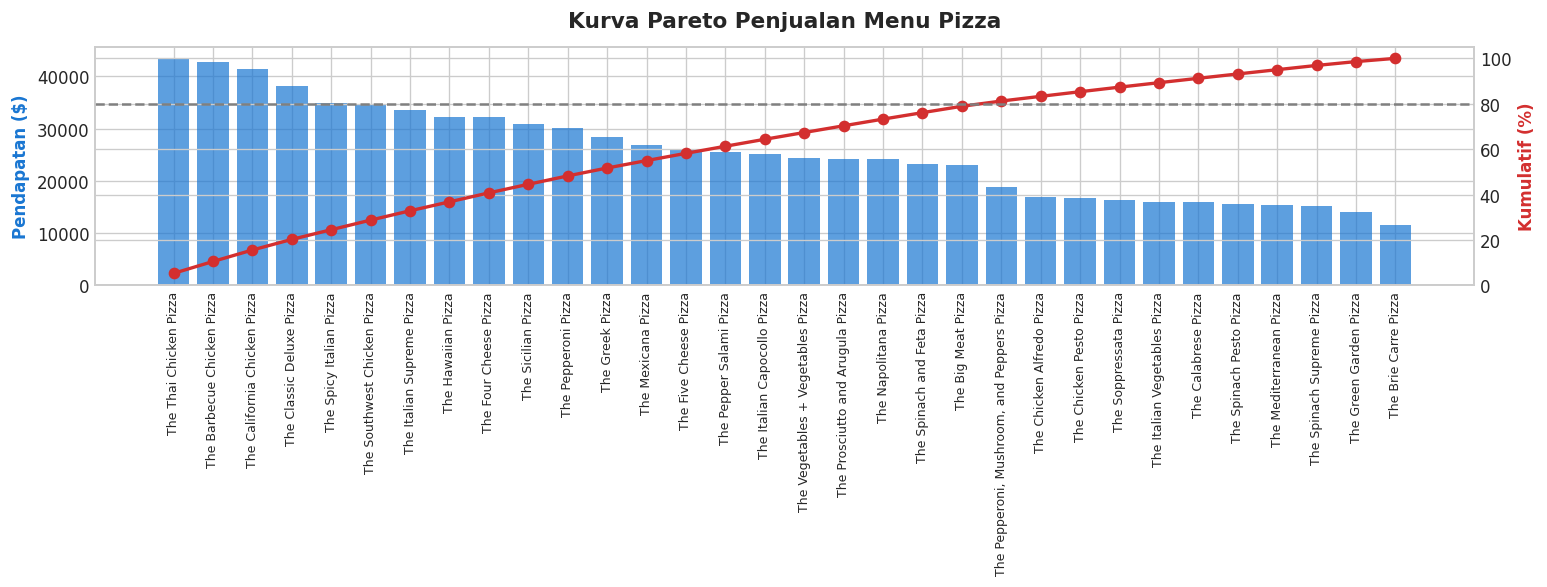

In [22]:
# Visualisasi Kurva Pareto 80/20
fig, ax1 = plt.subplots(figsize=(13, 5))

x = range(len(df_pareto))
ax1.bar(x, df_pareto['pizza_revenue'], color='#1976D2', alpha=0.7)
ax1.set_ylabel('Pendapatan ($)', color='#1976D2', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(df_pareto['pizza_name'], rotation=90, fontsize=7.5)

ax2 = ax1.twinx()
ax2.plot(x, df_pareto['cumulative_pct'], color='#D32F2F', marker='o', linewidth=2)
ax2.axhline(80, color='gray', linestyle='--', linewidth=1.5, label='Batas 80%')
ax2.set_ylabel('Kumulatif (%)', color='#D32F2F', fontweight='bold')
ax2.set_ylim(0, 105)

plt.title('Kurva Pareto Penjualan Menu Pizza', pad=12)
fig.tight_layout()
save_and_show(fig, '03_pareto_menu_curve.png')

In [23]:
# Query 5 & 6: Top 5 dan Bottom 5 Menu Berdasarkan Pendapatan
sql_top_bottom = '''
WITH RankedPizzas AS (
    SELECT 
        pizza_name, 
        pizza_category, 
        SUM(quantity) AS total_qty, 
        ROUND(SUM(total_price), 2) AS total_revenue,
        ROW_NUMBER() OVER(ORDER BY SUM(total_price) DESC) AS rank_desc,
        ROW_NUMBER() OVER(ORDER BY SUM(total_price) ASC) AS rank_asc
    FROM pizza_sales_clean 
    GROUP BY pizza_name, pizza_category
)
SELECT 
    CASE WHEN rank_desc <= 5 THEN 'Top 5 Terlaris' ELSE 'Bottom 5 Terendah' END AS kelompok,
    pizza_name,
    pizza_category,
    total_qty,
    total_revenue
FROM RankedPizzas
WHERE rank_desc <= 5 OR rank_asc <= 5
ORDER BY total_revenue DESC;
'''

df_top_bottom = pd.read_sql_query(sql_top_bottom, conn)
display(df_top_bottom)

,kelompok,pizza_name,pizza_category,total_qty,total_revenue
0,Top 5 Terlaris,The Thai Chicken Pizza,Chicken,2371,43434.25
1,Top 5 Terlaris,The Barbecue Chicken Pizza,Chicken,2432,42768.00
2,Top 5 Terlaris,The California Chicken Pizza,Chicken,2370,41409.50
3,Top 5 Terlaris,The Classic Deluxe Pizza,Classic,2453,38180.50
4,Top 5 Terlaris,The Spicy Italian Pizza,Supreme,1924,34831.25
5,Bottom 5 Terendah,The Spinach Pesto Pizza,Veggie,970,15596.00
6,Bottom 5 Terendah,The Mediterranean Pizza,Veggie,934,15360.50
7,Bottom 5 Terendah,The Spinach Supreme Pizza,Supreme,950,15277.75
8,Bottom 5 Terendah,The Green Garden Pizza,Veggie,997,13955.75
9,Bottom 5 Terendah,The Brie Carre Pizza,Supreme,490,11588.50


In [24]:
# Query 7: Distribusi Penjualan per Jam Operasional
sql_hourly = '''
SELECT 
    CAST(STRFTIME('%H', order_time) AS INTEGER) AS hour_of_day,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(quantity) AS total_pizzas,
    ROUND(SUM(total_price), 2) AS revenue,
    ROUND(SUM(total_price) / COUNT(DISTINCT order_id), 2) AS avg_ticket
FROM pizza_sales_clean
GROUP BY hour_of_day
ORDER BY hour_of_day;
'''

df_hourly = pd.read_sql_query(sql_hourly, conn)
display(df_hourly)

,hour_of_day,total_orders,total_pizzas,revenue,avg_ticket
0,NaN,1,4,83.00,83.00
1,10.0,8,18,303.65,37.96
2,11.0,1231,2728,44935.80,36.50
3,12.0,2520,6776,111877.90,44.40
4,13.0,2455,6413,106065.70,43.20
5,14.0,1472,3613,59201.40,40.22
6,15.0,1468,3216,52992.30,36.10
7,16.0,1920,4239,70055.40,36.49
8,17.0,2336,5211,86237.45,36.92
9,18.0,2399,5417,89296.85,37.22


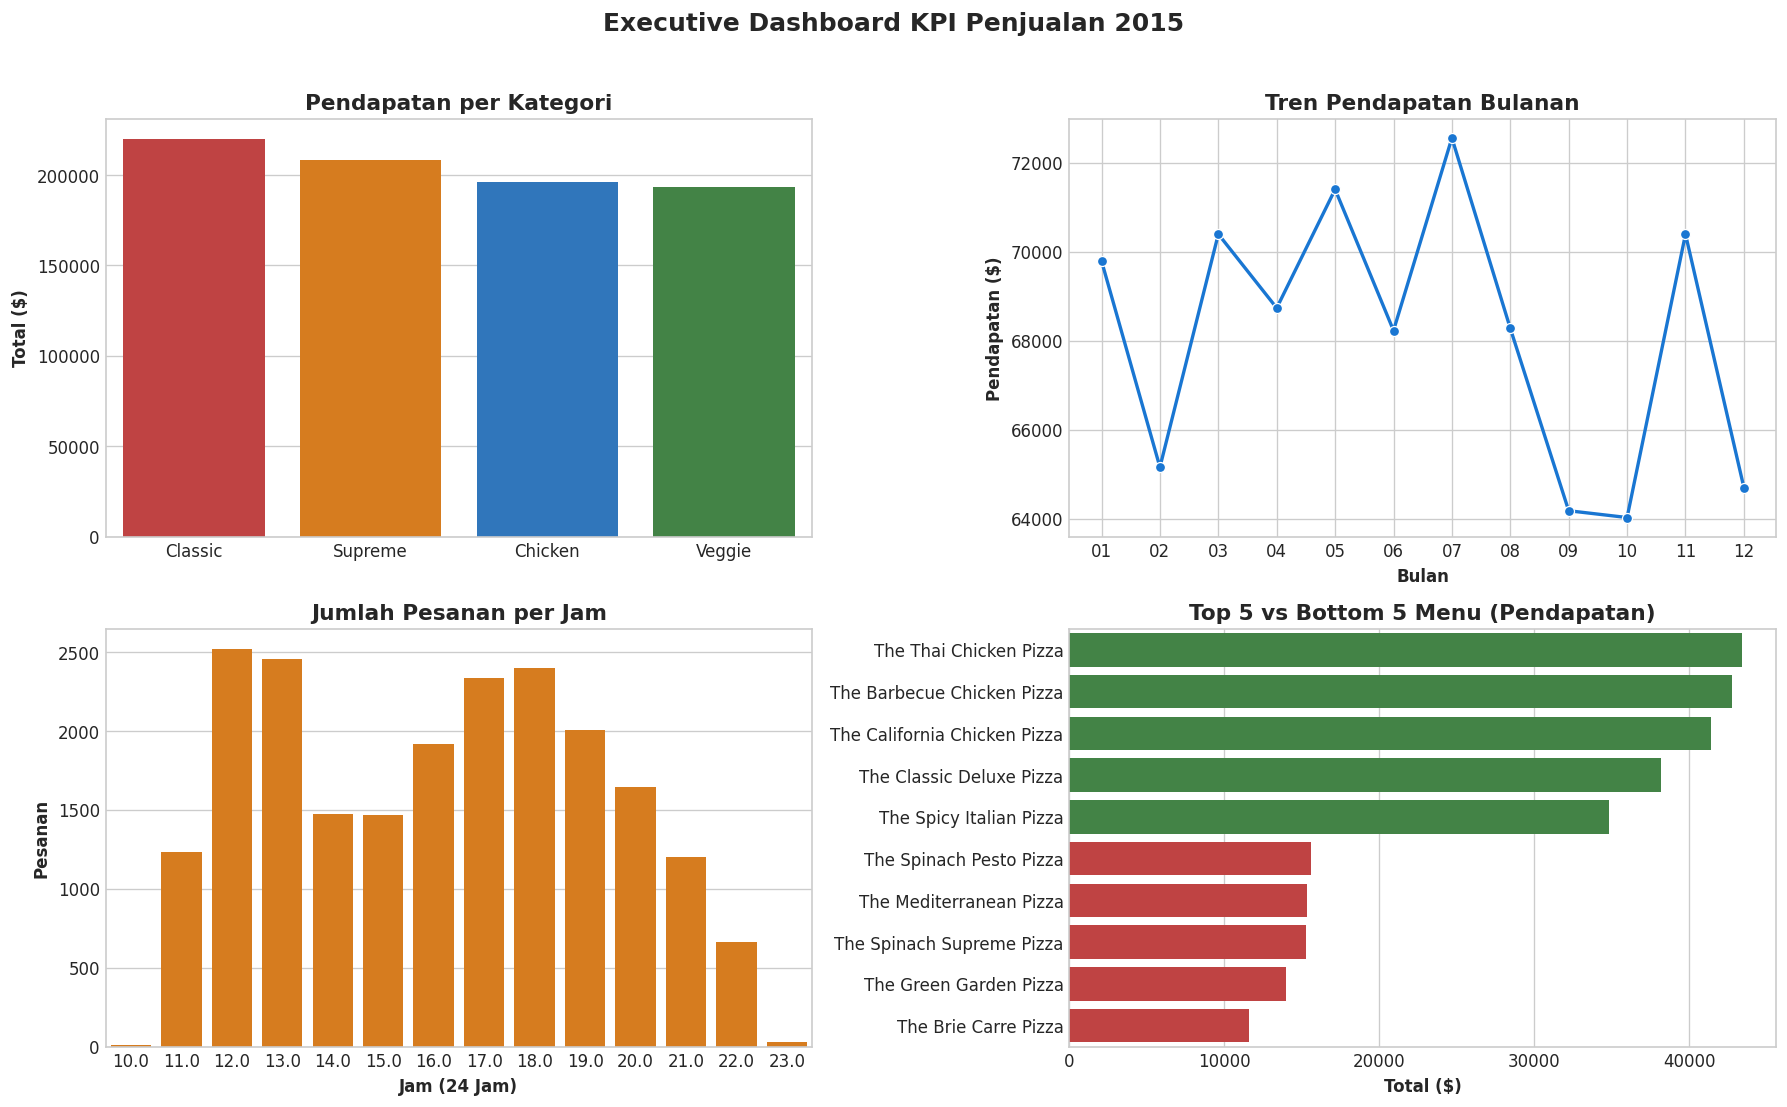

In [25]:
# Dashboard Visual KPI Eksekutif Berbasis SQL
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.barplot(data=df_cat_perf, x='pizza_category', y='category_revenue', palette=PALETTE_CATEGORIES, ax=axes[0, 0])
axes[0, 0].set_title('Pendapatan per Kategori')
axes[0, 0].set_ylabel('Total ($)')
axes[0, 0].set_xlabel('')

sns.lineplot(data=df_monthly, x='month_num', y='monthly_revenue', marker='o', color='#1976D2', linewidth=2, ax=axes[0, 1])
axes[0, 1].set_title('Tren Pendapatan Bulanan')
axes[0, 1].set_ylabel('Pendapatan ($)')
axes[0, 1].set_xlabel('Bulan')

sns.barplot(data=df_hourly, x='hour_of_day', y='total_orders', color='#F57C00', ax=axes[1, 0])
axes[1, 0].set_title('Jumlah Pesanan per Jam')
axes[1, 0].set_ylabel('Pesanan')
axes[1, 0].set_xlabel('Jam (24 Jam)')

colors = ['#388E3C']*5 + ['#D32F2F']*5
sns.barplot(data=df_top_bottom, y='pizza_name', x='total_revenue', palette=colors, ax=axes[1, 1])
axes[1, 1].set_title('Top 5 vs Bottom 5 Menu (Pendapatan)')
axes[1, 1].set_xlabel('Total ($)')
axes[1, 1].set_ylabel('')

plt.suptitle('Executive Dashboard KPI Penjualan 2015', y=1.02, fontsize=15, weight='bold')
plt.tight_layout()
save_and_show(fig, '04_sql_executive_dashboard.png')

---
# Bagian 5: Analisis Univariat
Pemeriksaan karakteristik sebaran data untuk masing-masing variabel secara individual.

In [26]:
qty_counts = df_clean['quantity'].value_counts().sort_index().reset_index()
qty_counts.columns = ['Quantity', 'Frekuensi']
qty_counts['Persentase'] = (qty_counts['Frekuensi'] / len(df_clean) * 100).round(2)
display(qty_counts)

,Quantity,Frekuensi,Persentase
0,1,47693,98.09
1,2,903,1.86
2,3,21,0.04
3,4,3,0.01


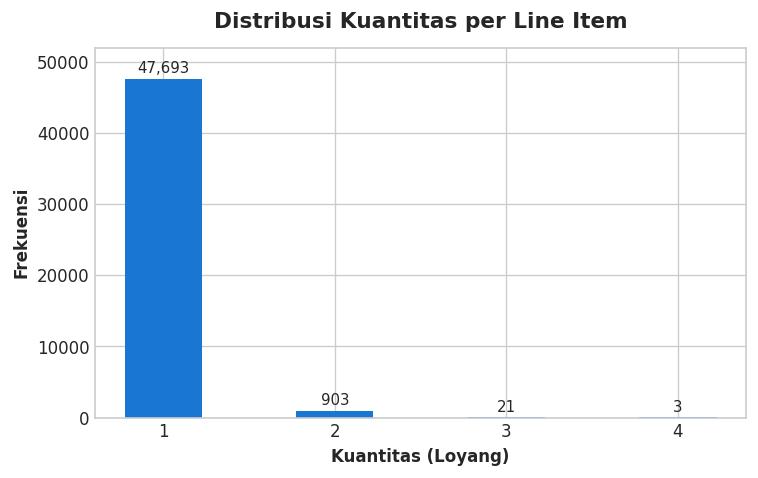

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(qty_counts['Quantity'].astype(str), qty_counts['Frekuensi'], color='#1976D2', width=0.45)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 400, f"{y:,}", ha='center', va='bottom', fontsize=9)

plt.title('Distribusi Kuantitas per Line Item', pad=12)
plt.xlabel('Kuantitas (Loyang)')
plt.ylabel('Frekuensi')
plt.ylim(0, 52000)
save_and_show(fig, '05_univariate_quantity_distribution.png')

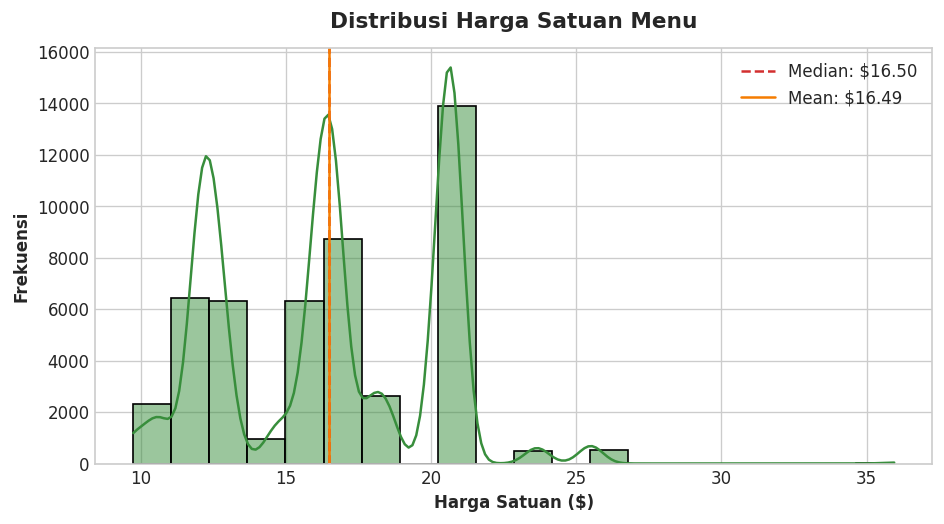

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df_clean['unit_price'], bins=20, kde=True, color='#388E3C', ax=ax)
median_p = df_clean['unit_price'].median()
mean_p = df_clean['unit_price'].mean()

ax.axvline(median_p, color='#D32F2F', linestyle='--', label=f'Median: ${median_p:.2f}')
ax.axvline(mean_p, color='#F57C00', linestyle='-', label=f'Mean: ${mean_p:.2f}')
plt.title('Distribusi Harga Satuan Menu', pad=12)
plt.xlabel('Harga Satuan ($)')
plt.ylabel('Frekuensi')
plt.legend()
save_and_show(fig, '06_univariate_unit_price_kde.png')

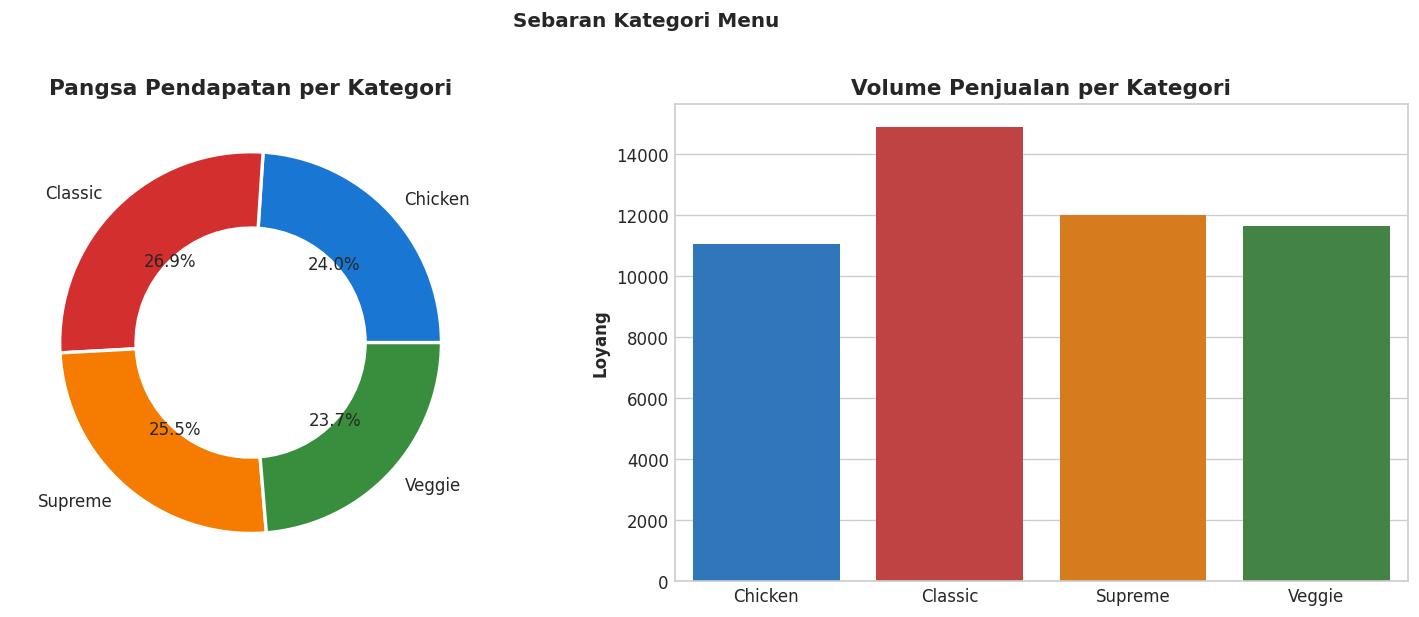

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cat_data = df_clean.groupby('pizza_category').agg(Revenue=('total_price', 'sum'), Quantity=('quantity', 'sum'))

axes[0].pie(cat_data['Revenue'], labels=cat_data.index, autopct='%1.1f%%', colors=[PALETTE_CATEGORIES[c] for c in cat_data.index],
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0].set_title('Pangsa Pendapatan per Kategori')

sns.barplot(x=cat_data.index, y=cat_data['Quantity'], palette=PALETTE_CATEGORIES, ax=axes[1])
axes[1].set_title('Volume Penjualan per Kategori')
axes[1].set_ylabel('Loyang')
axes[1].set_xlabel('')

plt.suptitle('Sebaran Kategori Menu', y=1.02, weight='bold')
plt.tight_layout()
save_and_show(fig, '07_univariate_category_shares.png')

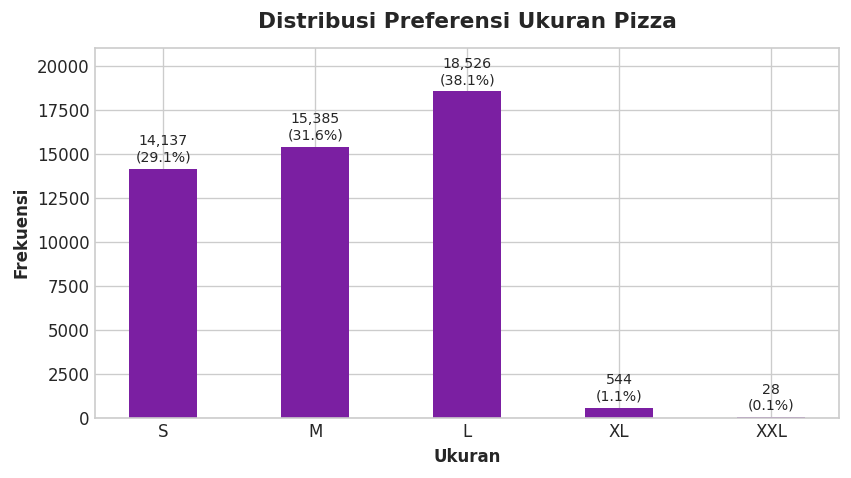

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
size_order = ['S', 'M', 'L', 'XL', 'XXL']
size_counts = df_clean['pizza_size'].value_counts().loc[size_order]

bars = ax.bar(size_counts.index, size_counts.values, color='#7B1FA2', width=0.45)
for bar in bars:
    y = bar.get_height()
    pct = (y / len(df_clean)) * 100
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 250, f"{y:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=8.5)

plt.title('Distribusi Preferensi Ukuran Pizza', pad=12)
plt.xlabel('Ukuran')
plt.ylabel('Frekuensi')
plt.ylim(0, 21000)
save_and_show(fig, '08_univariate_size_distribution.png')

---
# Bagian 6: Analisis Bivariat dan Multivariat
Pemeriksaan hubungan dan interaksi antar variabel kunci.

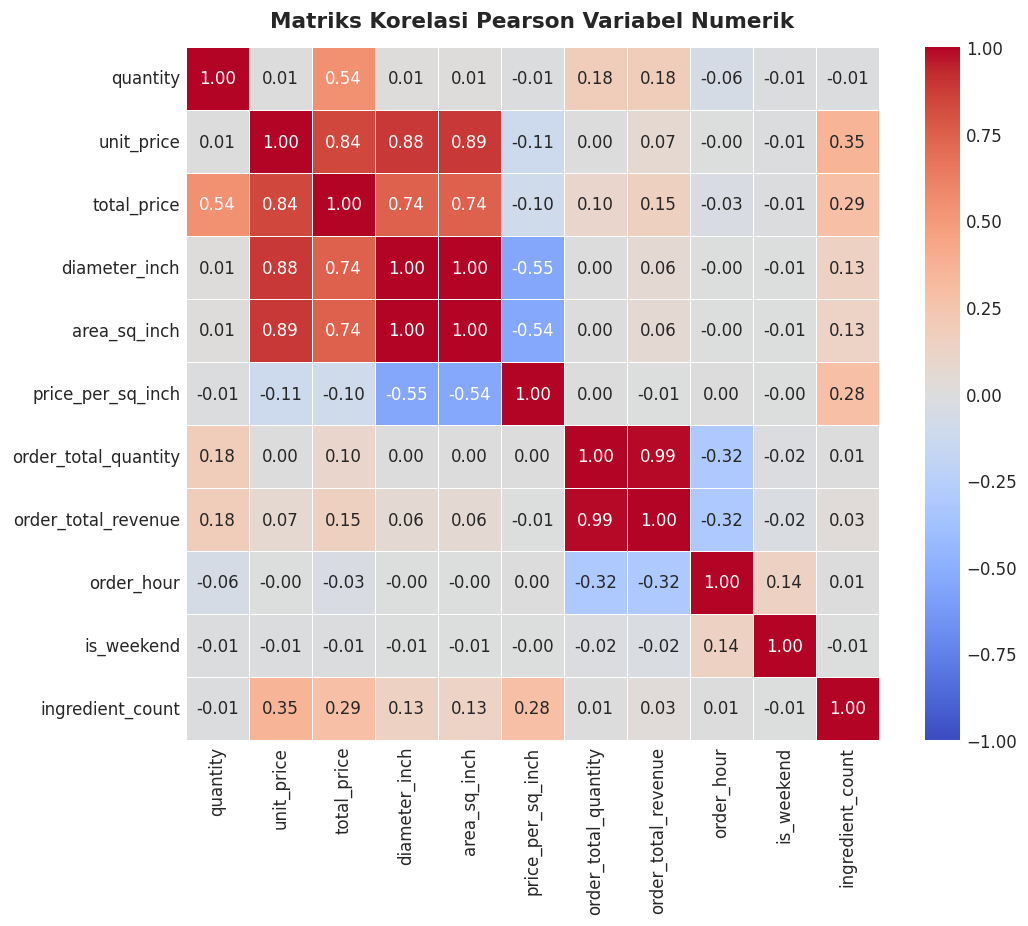

In [31]:
corr_vars = ['quantity', 'unit_price', 'total_price', 'diameter_inch', 'area_sq_inch', 'price_per_sq_inch', 
             'order_total_quantity', 'order_total_revenue', 'order_hour', 'is_weekend', 'ingredient_count']
corr_matrix = df_wide[corr_vars].corr()

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax, linewidths=0.5)
plt.title('Matriks Korelasi Pearson Variabel Numerik', pad=12)
save_and_show(fig, '09_correlation_matrix_heatmap.png')

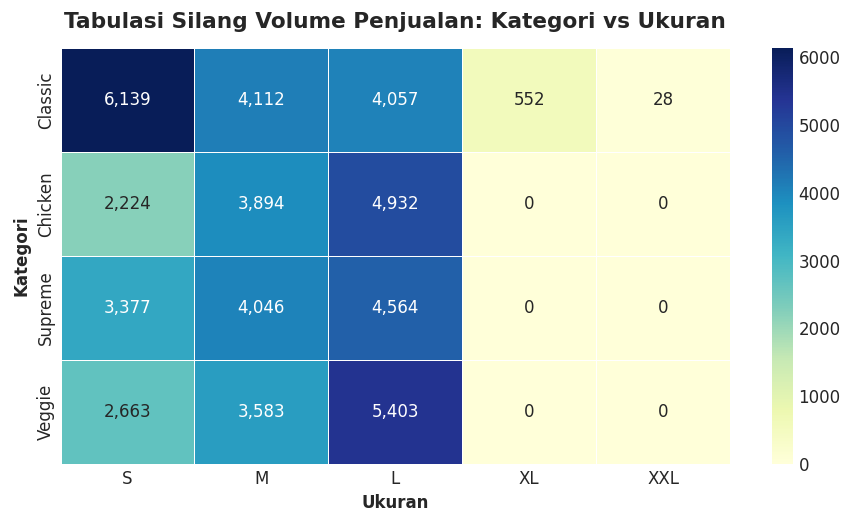

In [32]:
cat_size_crosstab = pd.crosstab(df_clean['pizza_category'], df_clean['pizza_size'], values=df_clean['quantity'], aggfunc='sum').loc[['Classic', 'Chicken', 'Supreme', 'Veggie'], ['S', 'M', 'L', 'XL', 'XXL']].fillna(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(cat_size_crosstab, annot=True, fmt=',.0f', cmap='YlGnBu', ax=ax, linewidths=0.5)
plt.title('Tabulasi Silang Volume Penjualan: Kategori vs Ukuran', pad=12)
plt.ylabel('Kategori')
plt.xlabel('Ukuran')
save_and_show(fig, '10_bivariate_cat_size_heatmap.png')

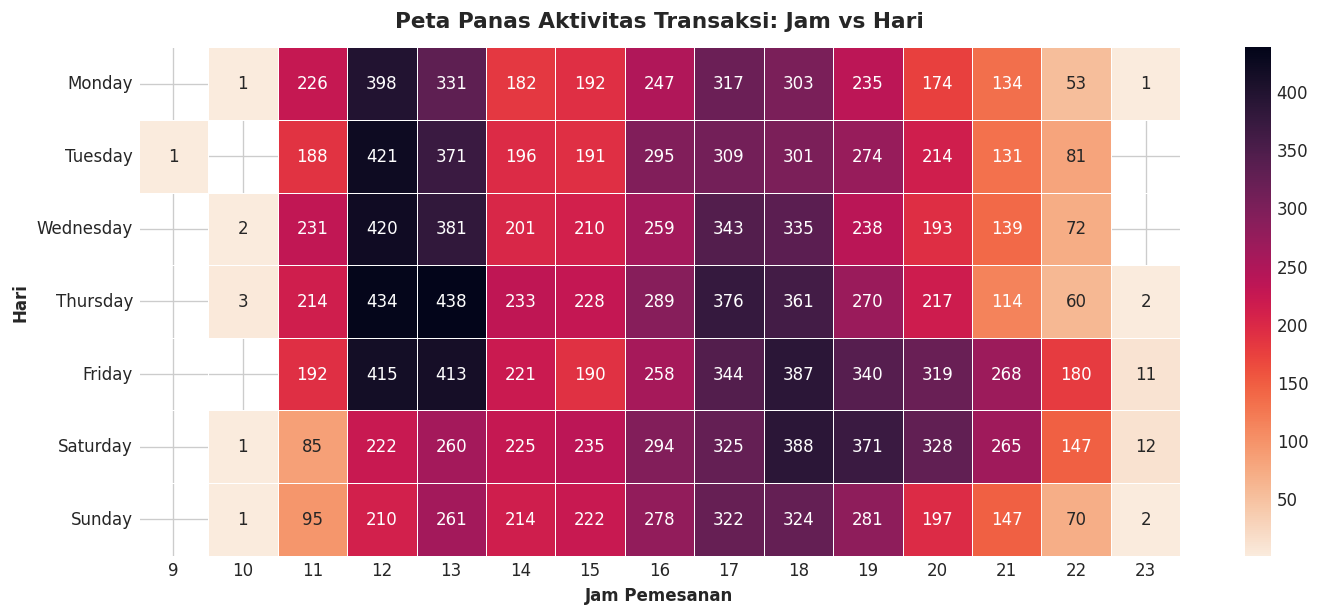

In [33]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly_day_pivot = df_wide.pivot_table(index='order_day_name', columns='order_hour', values='order_id', aggfunc='nunique').reindex(day_order)

fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(hourly_day_pivot, cmap='rocket_r', annot=True, fmt='.0f', linewidths=0.5, ax=ax)
plt.title('Peta Panas Aktivitas Transaksi: Jam vs Hari', pad=12)
plt.xlabel('Jam Pemesanan')
plt.ylabel('Hari')
save_and_show(fig, '11_hourly_day_traffic_heatmap.png')

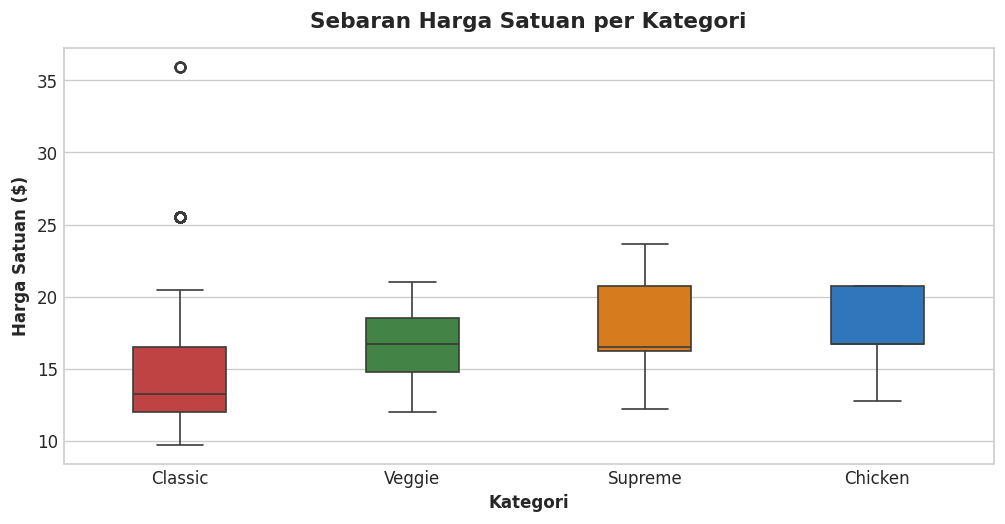

In [34]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df_clean, x='pizza_category', y='unit_price', palette=PALETTE_CATEGORIES, ax=ax, width=0.4)
plt.title('Sebaran Harga Satuan per Kategori', pad=12)
plt.xlabel('Kategori')
plt.ylabel('Harga Satuan ($)')
save_and_show(fig, '12_bivariate_price_category_boxstrip.png')

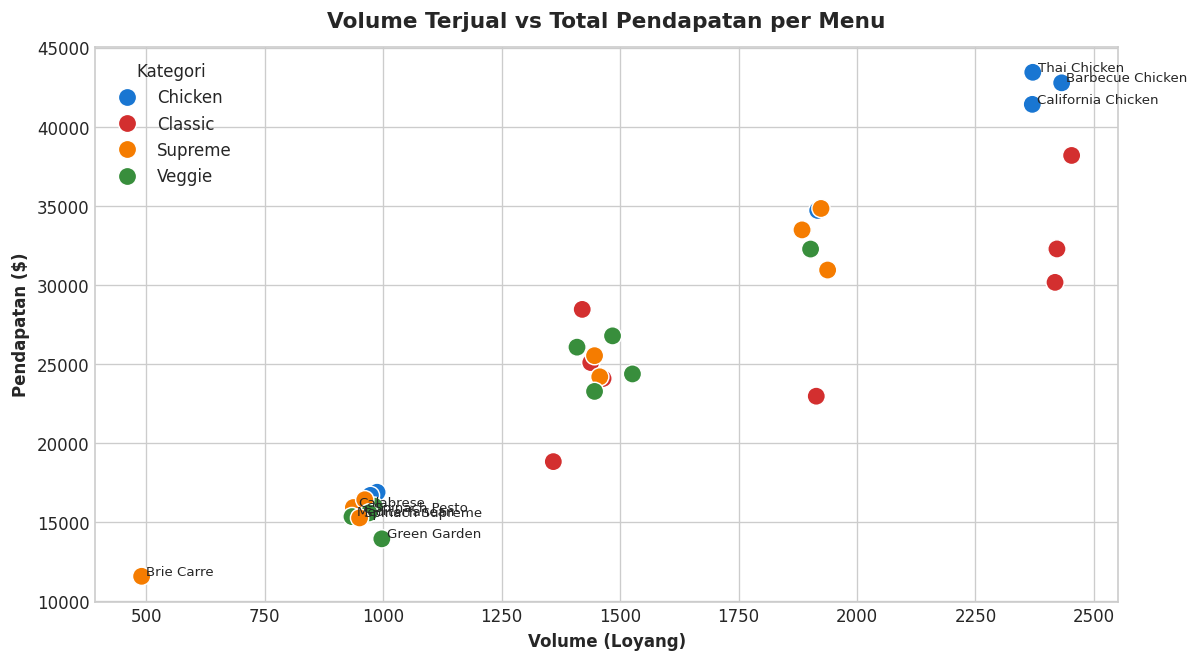

In [35]:
pizza_scatter = df_clean.groupby(['pizza_name', 'pizza_category']).agg(
    total_qty=('quantity', 'sum'),
    total_rev=('total_price', 'sum')
).reset_index()

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=pizza_scatter, x='total_qty', y='total_rev', hue='pizza_category', palette=PALETTE_CATEGORIES, s=120, ax=ax)

for _, row in pizza_scatter.iterrows():
    if row['total_rev'] > 40000 or row['total_rev'] < 16000:
        ax.annotate(row['pizza_name'].replace('The ', '').replace(' Pizza', ''), (row['total_qty']+10, row['total_rev']+100), fontsize=8)

plt.title('Volume Terjual vs Total Pendapatan per Menu', pad=12)
plt.xlabel('Volume (Loyang)')
plt.ylabel('Pendapatan ($)')
plt.legend(title='Kategori', loc='upper left')
save_and_show(fig, '13_scatter_volume_vs_revenue.png')

---
# Bagian 7: Analisis Temporal dan Deret Waktu
Eksplorasi tren harian sepanjang 358 hari operasional, identifikasi hari ekstrem, dan perbandingan jendela jam makan.

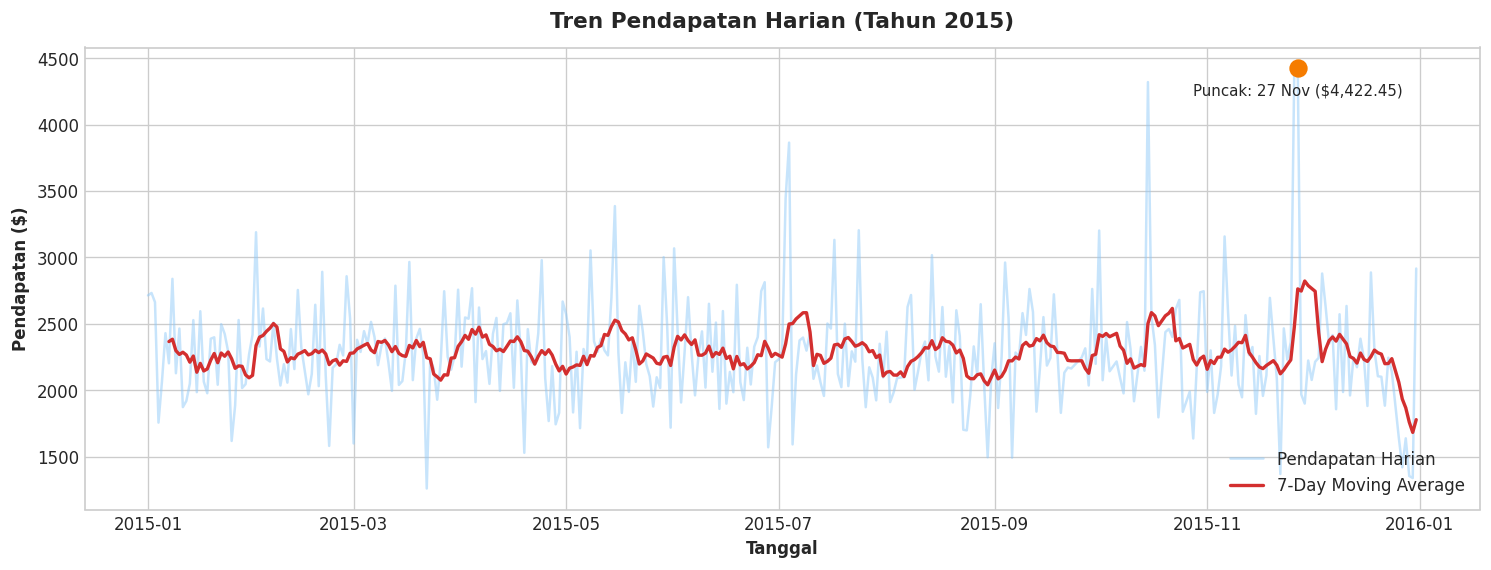

In [36]:
daily_sales = df_clean.groupby('order_date_parsed').agg(
    daily_revenue=('total_price', 'sum'),
    daily_orders=('order_id', 'nunique'),
    daily_pizzas=('quantity', 'sum')
).reset_index()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_sales['order_date_parsed'], daily_sales['daily_revenue'], color='#90CAF9', alpha=0.5, label='Pendapatan Harian')
ax.plot(daily_sales['order_date_parsed'], daily_sales['daily_revenue'].rolling(7).mean(), color='#D32F2F', linewidth=2, label='7-Day Moving Average')

top_day = daily_sales.loc[daily_sales['daily_revenue'].idxmax()]
ax.scatter([top_day['order_date_parsed']], [top_day['daily_revenue']], color='#F57C00', s=100, zorder=5)
ax.annotate(f"Puncak: {top_day['order_date_parsed'].strftime('%d %b')} (${top_day['daily_revenue']:,.2f})", 
            (top_day['order_date_parsed'], top_day['daily_revenue']-200), fontsize=9, ha='center')

plt.title('Tren Pendapatan Harian (Tahun 2015)', pad=12)
plt.xlabel('Tanggal')
plt.ylabel('Pendapatan ($)')
plt.legend(loc='lower right')
save_and_show(fig, '14_daily_revenue_timeseries.png')

In [37]:
top_5_days = daily_sales.sort_values('daily_revenue', ascending=False).head(5)[['order_date_parsed', 'daily_revenue', 'daily_orders', 'daily_pizzas']].copy()
bottom_5_days = daily_sales.sort_values('daily_revenue', ascending=True).head(5)[['order_date_parsed', 'daily_revenue', 'daily_orders', 'daily_pizzas']].copy()

print("5 Hari dengan Pendapatan Tertinggi:")
display(top_5_days)
print("5 Hari dengan Pendapatan Terendah:")
display(bottom_5_days)

5 Hari dengan Pendapatan Tertinggi:


,order_date_parsed,daily_revenue,daily_orders,daily_pizzas
324,2015-11-27,4422.45,115,264
323,2015-11-26,4405.95,113,266
283,2015-10-15,4320.20,107,262
184,2015-07-04,3864.20,105,234
183,2015-07-03,3443.00,93,213


5 Hari dengan Pendapatan Terendah:


,order_date_parsed,daily_revenue,daily_orders,daily_pizzas
80,2015-03-22,1259.25,37,77
356,2015-12-30,1337.80,32,82
355,2015-12-29,1353.25,27,80
319,2015-11-22,1368.70,43,84
353,2015-12-27,1419.00,35,89


In [38]:
period_summary = df_wide.groupby('time_period').agg(
    total_revenue=('total_price', 'sum'),
    total_orders=('order_id', 'nunique'),
    total_pizzas=('quantity', 'sum'),
    avg_ticket=('order_total_revenue', 'mean')
).sort_values('total_revenue', ascending=False)

period_summary['pct_revenue'] = (period_summary['total_revenue'] / period_summary['total_revenue'].sum() * 100).round(2)
display(period_summary)

,total_revenue,total_orders,total_pizzas,avg_ticket,pct_revenue
time_period,,,,,
Lunch Rush (11:00-14:59),322080.80,7678,19530,84.716426,39.38
Dinner Rush (17:00-20:59),306378.60,8386,18568,44.772995,37.46
Afternoon Lull (15:00-16:59),123047.70,3388,7455,47.537974,15.05
Late Evening (>=21:00),65966.30,1889,3999,44.114095,8.07
Morning Prep (<11:00),386.65,9,22,50.585714,0.05


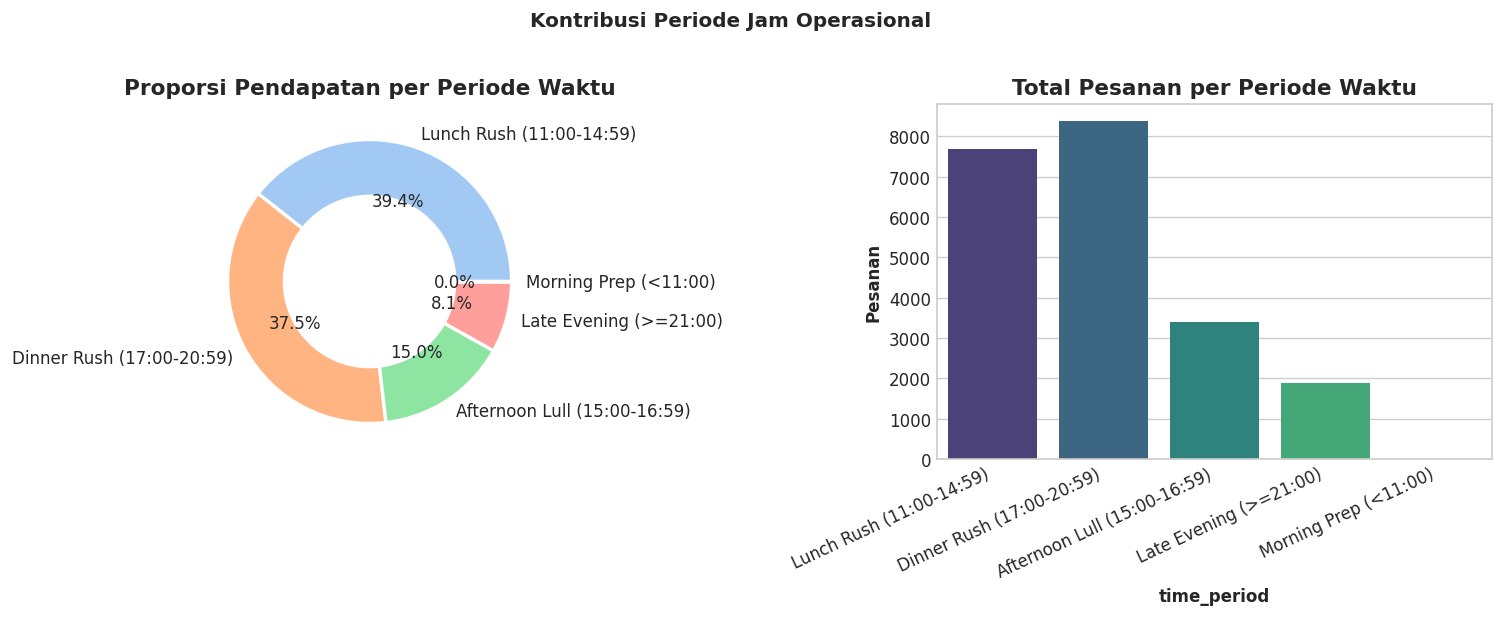

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].pie(period_summary['total_revenue'], labels=period_summary.index, autopct='%1.1f%%', 
            colors=sns.color_palette('pastel'), wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0].set_title('Proporsi Pendapatan per Periode Waktu')

sns.barplot(x=period_summary.index, y=period_summary['total_orders'], palette='viridis', ax=axes[1])
axes[1].set_title('Total Pesanan per Periode Waktu')
axes[1].set_ylabel('Pesanan')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=25, ha='right')

plt.suptitle('Kontribusi Periode Jam Operasional', y=1.02, weight='bold')
plt.tight_layout()
save_and_show(fig, '15_time_period_contributions.png')

---
# Bagian 8: Menu Engineering Matrix (Kasavana & Smith)
Evaluasi portofolio 32 varian menu berdasarkan volume penjualan (Popularitas) dan kontribusi pendapatan kotor.

In [40]:
menu_eng = df_clean.groupby(['pizza_name', 'pizza_category']).agg(
    total_sold=('quantity', 'sum'),
    total_revenue=('total_price', 'sum'),
    avg_price=('unit_price', 'mean')
).reset_index()

avg_sold_benchmark = menu_eng['total_sold'].mean()
avg_rev_benchmark = menu_eng['total_revenue'].mean()

def classify_menu(row):
    high_pop = row['total_sold'] >= avg_sold_benchmark
    high_rev = row['total_revenue'] >= avg_rev_benchmark
    if high_pop and high_rev:
        return 'Stars (High Vol, High Rev)'
    elif high_pop and not high_rev:
        return 'Plowhorses (High Vol, Low Rev)'
    elif not high_pop and high_rev:
        return 'Puzzles (Low Vol, High Rev)'
    else:
        return 'Underperformers (Low Vol, Low Rev)'

menu_eng['menu_quadrant'] = menu_eng.apply(classify_menu, axis=1)

print(f"Rata-rata volume menu: {avg_sold_benchmark:,.0f} loyang | Rata-rata pendapatan menu: ${avg_rev_benchmark:,.2f}")
display(menu_eng['menu_quadrant'].value_counts())

Rata-rata volume menu: 1,549 loyang | Rata-rata pendapatan menu: $25,558.13


menu_quadrant
Underperformers (Low Vol, Low Rev)    17
Stars (High Vol, High Rev)            11
Puzzles (Low Vol, High Rev)            3
Plowhorses (High Vol, Low Rev)         1
Name: count, dtype: int64

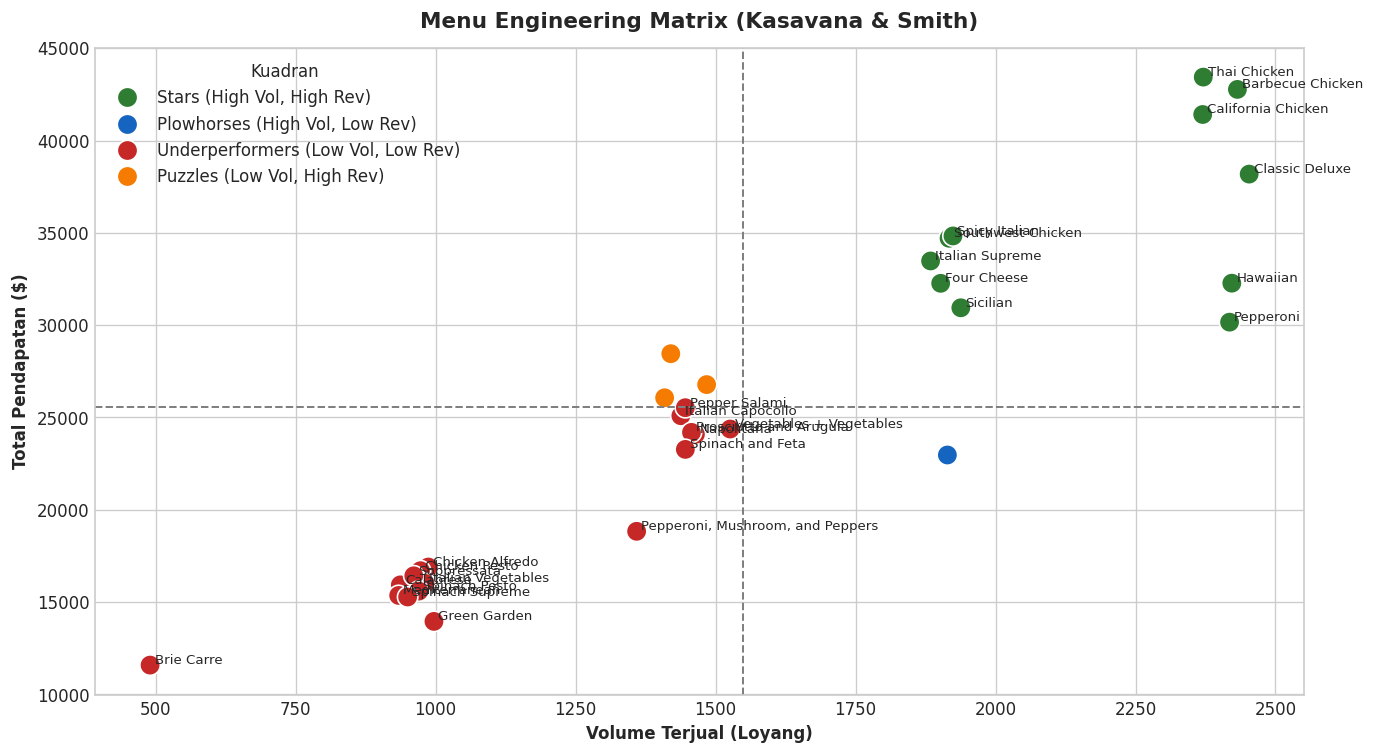

In [41]:
fig, ax = plt.subplots(figsize=(13, 7))

quadrant_colors = {
    'Stars (High Vol, High Rev)': '#2E7D32',
    'Plowhorses (High Vol, Low Rev)': '#1565C0',
    'Puzzles (Low Vol, High Rev)': '#F57C00',
    'Underperformers (Low Vol, Low Rev)': '#C62828'
}

sns.scatterplot(data=menu_eng, x='total_sold', y='total_revenue', hue='menu_quadrant', palette=quadrant_colors, s=150, ax=ax)
ax.axvline(avg_sold_benchmark, color='gray', linestyle='--', linewidth=1.2)
ax.axhline(avg_rev_benchmark, color='gray', linestyle='--', linewidth=1.2)

for _, row in menu_eng.iterrows():
    if row['menu_quadrant'] in ['Stars (High Vol, High Rev)', 'Underperformers (Low Vol, Low Rev)']:
        ax.annotate(row['pizza_name'].replace('The ', '').replace(' Pizza', ''), (row['total_sold']+8, row['total_revenue']+80), fontsize=8)

plt.title('Menu Engineering Matrix (Kasavana & Smith)', pad=12)
plt.xlabel('Volume Terjual (Loyang)')
plt.ylabel('Total Pendapatan ($)')
plt.legend(title='Kuadran', loc='upper left')
save_and_show(fig, '16_menu_engineering_matrix.png')

In [42]:
stars_list = menu_eng[menu_eng['menu_quadrant'] == 'Stars (High Vol, High Rev)'].sort_values('total_revenue', ascending=False)
under_list = menu_eng[menu_eng['menu_quadrant'] == 'Underperformers (Low Vol, Low Rev)'].sort_values('total_revenue', ascending=True)

print("Menu Stars:")
display(stars_list[['pizza_name', 'pizza_category', 'total_sold', 'total_revenue', 'avg_price']])
print("Menu Underperformers:")
display(under_list[['pizza_name', 'pizza_category', 'total_sold', 'total_revenue', 'avg_price']])

Menu Stars:


,pizza_name,pizza_category,total_sold,total_revenue,avg_price
30,The Thai Chicken Pizza,Chicken,2371,43434.25,18.286069
0,The Barbecue Chicken Pizza,Chicken,2432,42768.00,17.572934
4,The California Chicken Pizza,Chicken,2370,41409.50,17.448523
7,The Classic Deluxe Pizza,Classic,2453,38180.50,15.575952
26,The Spicy Italian Pizza,Supreme,1924,34831.25,18.104663
25,The Southwest Chicken Pizza,Chicken,1917,34705.75,18.080504
14,The Italian Supreme Pizza,Supreme,1884,33476.75,17.769740
12,The Hawaiian Pizza,Classic,2422,32273.25,13.317194
9,The Four Cheese Pizza,Veggie,1902,32265.70,16.951946
23,The Sicilian Pizza,Supreme,1938,30940.50,15.963831


Menu Underperformers:


,pizza_name,pizza_category,total_sold,total_revenue,avg_price
2,The Brie Carre Pizza,Supreme,490,11588.50,23.650000
11,The Green Garden Pizza,Veggie,997,13955.75,14.001520
28,The Spinach Supreme Pizza,Supreme,950,15277.75,16.089362
16,The Mediterranean Pizza,Veggie,934,15360.50,16.427952
27,The Spinach Pesto Pizza,Veggie,970,15596.00,16.079676
3,The Calabrese Pizza,Supreme,937,15934.25,17.005124
15,The Italian Vegetables Pizza,Veggie,981,16019.25,16.339231
24,The Soppressata Pizza,Supreme,961,16425.75,17.077064
6,The Chicken Pesto Pizza,Chicken,973,16701.75,17.153746
5,The Chicken Alfredo Pizza,Chicken,987,16900.25,17.121429


---
# Bagian 9: Analisis Kebutuhan Bahan Baku dan Rantai Pasok
Perhitungan kebutuhan 65 bahan baku berdasarkan loyang yang diproduksi dan estimasi kebutuhan stok mingguan.

In [43]:
ingredient_consumption = {}
for _, row in df_clean.iterrows():
    qty = row['quantity']
    ings = [i.strip() for i in row['pizza_ingredients'].split(',')]
    for ing in ings:
        ingredient_consumption[ing] = ingredient_consumption.get(ing, 0) + qty

df_ing_demand = pd.DataFrame(list(ingredient_consumption.items()), columns=['Nama_Bahan', 'Total_Loyang_Memerlukan'])
df_ing_demand = df_ing_demand.sort_values('Total_Loyang_Memerlukan', ascending=False).reset_index(drop=True)
df_ing_demand['Persentase_Produksi'] = (df_ing_demand['Total_Loyang_Memerlukan'] / df_clean['quantity'].sum() * 100).round(2)

def categorize_ingredient(ing):
    ing_lower = ing.lower()
    if 'cheese' in ing_lower:
        return 'Keju'
    elif any(m in ing_lower for m in ['chicken', 'beef', 'salami', 'pepperoni', 'ham', 'bacon', 'capocollo', 'pork', 'sausage', 'anchovies', 'prosciutto']):
        return 'Daging & Seafood'
    elif any(s in ing_lower for s in ['sauce', 'garlic', 'oil', 'cilantro', 'oregano']):
        return 'Bumbu & Saus'
    else:
        return 'Sayuran & Buah'

df_ing_demand['Kategori'] = df_ing_demand['Nama_Bahan'].apply(categorize_ingredient)
display(df_ing_demand.head(20))

,Nama_Bahan,Total_Loyang_Memerlukan,Persentase_Produksi,Kategori
0,Garlic,27913,56.31,Bumbu & Saus
1,Tomatoes,27052,54.57,Sayuran & Buah
2,Red Onions,19834,40.01,Sayuran & Buah
3,Red Peppers,16562,33.41,Sayuran & Buah
4,Mozzarella Cheese,10569,21.32,Keju
5,Pepperoni,10540,21.26,Daging & Seafood
6,Spinach,10166,20.51,Sayuran & Buah
7,Mushrooms,9729,19.63,Sayuran & Buah
8,Chicken,8618,17.38,Daging & Seafood
9,Capocollo,6692,13.50,Daging & Seafood


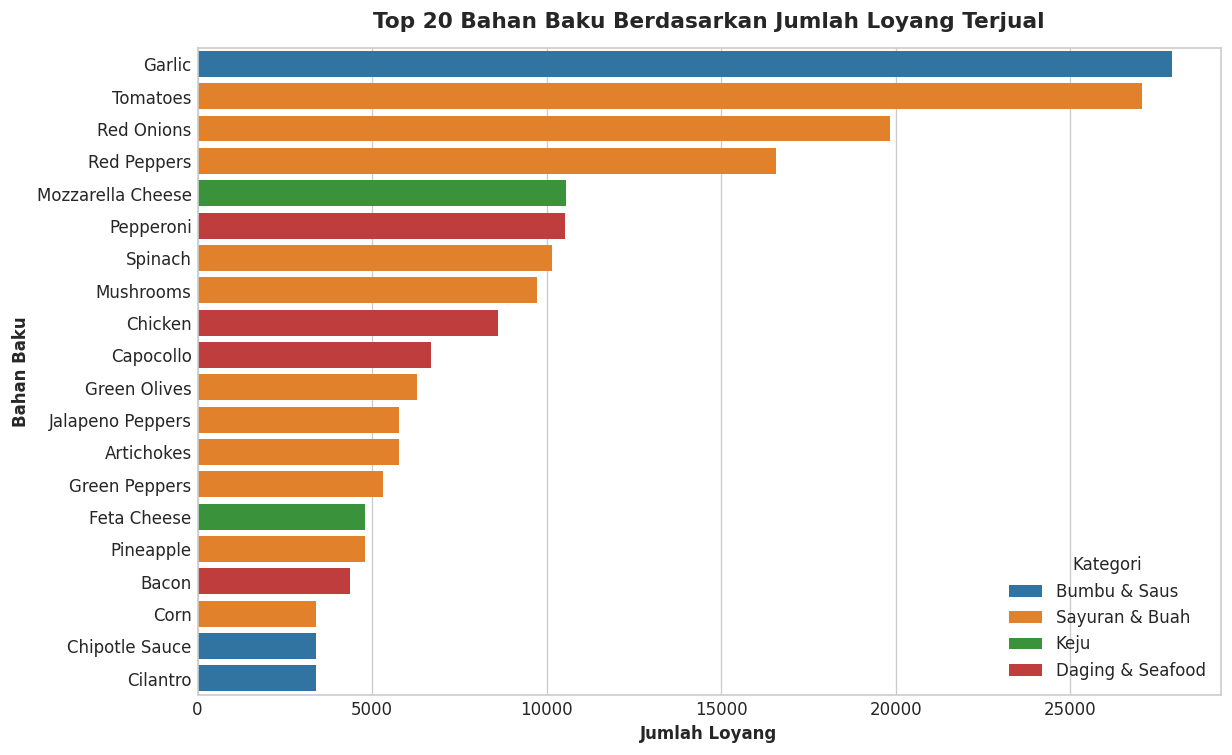

In [44]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=df_ing_demand.head(20), y='Nama_Bahan', x='Total_Loyang_Memerlukan', hue='Kategori', dodge=False, ax=ax)
plt.title('Top 20 Bahan Baku Berdasarkan Jumlah Loyang Terjual', pad=12)
plt.xlabel('Jumlah Loyang')
plt.ylabel('Bahan Baku')
save_and_show(fig, '17_top_20_ingredient_demand.png')

In [45]:
WEEKS = 51.14
top_10_ing = df_ing_demand.head(10).copy()
top_10_ing['Kebutuhan_Mingguan'] = (top_10_ing['Total_Loyang_Memerlukan'] / WEEKS).round(1)
top_10_ing['Safety_Stock_25pct'] = (top_10_ing['Kebutuhan_Mingguan'] * 1.25).round(1)
display(top_10_ing[['Nama_Bahan', 'Kategori', 'Total_Loyang_Memerlukan', 'Kebutuhan_Mingguan', 'Safety_Stock_25pct']])

,Nama_Bahan,Kategori,Total_Loyang_Memerlukan,Kebutuhan_Mingguan,Safety_Stock_25pct
0,Garlic,Bumbu & Saus,27913,545.8,682.2
1,Tomatoes,Sayuran & Buah,27052,529.0,661.2
2,Red Onions,Sayuran & Buah,19834,387.8,484.8
3,Red Peppers,Sayuran & Buah,16562,323.9,404.9
4,Mozzarella Cheese,Keju,10569,206.7,258.4
5,Pepperoni,Daging & Seafood,10540,206.1,257.6
6,Spinach,Sayuran & Buah,10166,198.8,248.5
7,Mushrooms,Sayuran & Buah,9729,190.2,237.8
8,Chicken,Daging & Seafood,8618,168.5,210.6
9,Capocollo,Daging & Seafood,6692,130.9,163.6


---
# Bagian 10: Market Basket Analysis dan Aturan Asosiasi
Identifikasi pasangan menu yang dibeli bersamaan pada pesanan multi-item untuk perancangan paket promo bundling.

In [46]:
multi_item_orders = df_clean.groupby('order_id').filter(lambda x: len(x) > 1)
basket = multi_item_orders.groupby('order_id')['pizza_name'].apply(lambda x: sorted(list(set(x)))).tolist()
total_baskets = df_clean['order_id'].nunique()

single_counts = {}
pair_counts = {}

for items in basket:
    for i in items:
        single_counts[i] = single_counts.get(i, 0) + 1
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            pair = tuple(sorted([items[i], items[j]]))
            pair_counts[pair] = pair_counts.get(pair, 0) + 1

rules = []
for (item_a, item_b), count_ab in pair_counts.items():
    supp_ab = count_ab / total_baskets
    supp_a = single_counts[item_a] / total_baskets
    supp_b = single_counts[item_b] / total_baskets
    conf_a_to_b = supp_ab / supp_a
    lift = supp_ab / (supp_a * supp_b)
    
    rules.append({
        'Item_A': item_a,
        'Item_B': item_b,
        'Co_occurrence': count_ab,
        'Support (%)': round(supp_ab * 100, 3),
        'Confidence (%)': round(conf_a_to_b * 100, 2),
        'Lift': round(lift, 2)
    })

df_rules = pd.DataFrame(rules).sort_values('Co_occurrence', ascending=False).reset_index(drop=True)
display(df_rules.head(15))

,Item_A,Item_B,Co_occurrence,Support (%),Confidence (%),Lift
0,The Hawaiian Pizza,The Thai Chicken Pizza,270,1.265,14.64,1.69
1,The Barbecue Chicken Pizza,The Pepperoni Pizza,269,1.260,14.35,1.60
2,The Hawaiian Pizza,The Pepperoni Pizza,259,1.213,14.05,1.56
3,The Pepperoni Pizza,The Thai Chicken Pizza,257,1.204,13.40,1.55
4,The California Chicken Pizza,The Pepperoni Pizza,256,1.199,14.12,1.57
5,The Barbecue Chicken Pizza,The Hawaiian Pizza,255,1.194,13.60,1.57
6,The Classic Deluxe Pizza,The Hawaiian Pizza,253,1.185,13.25,1.53
7,The Classic Deluxe Pizza,The Pepperoni Pizza,251,1.176,13.15,1.46
8,The Classic Deluxe Pizza,The Thai Chicken Pizza,250,1.171,13.10,1.51
9,The Barbecue Chicken Pizza,The California Chicken Pizza,249,1.166,13.28,1.56


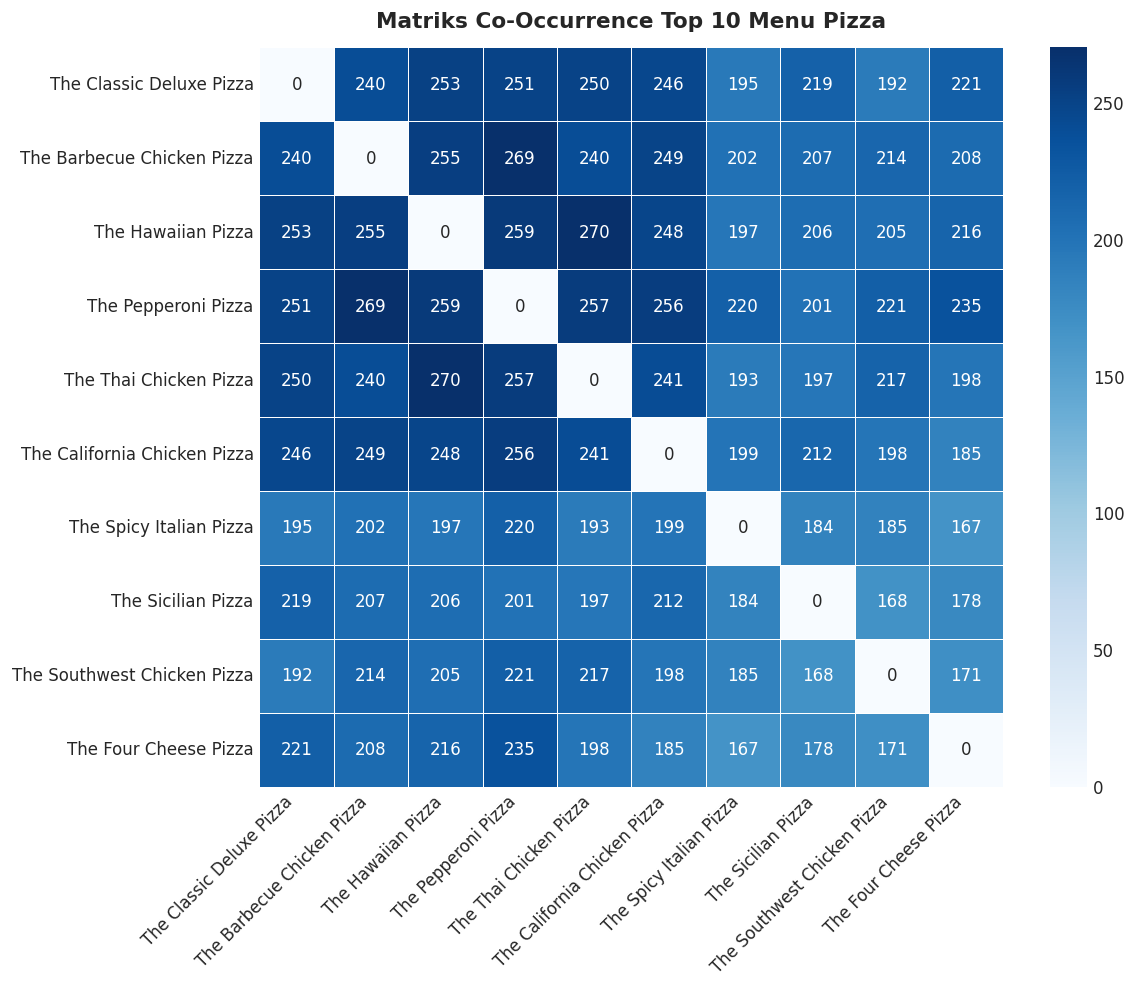

In [47]:
top_10_pizzas = df_clean['pizza_name'].value_counts().head(10).index.tolist()
co_matrix = pd.DataFrame(0, index=top_10_pizzas, columns=top_10_pizzas)

for (item_a, item_b), count in pair_counts.items():
    if item_a in top_10_pizzas and item_b in top_10_pizzas:
        co_matrix.loc[item_a, item_b] = count
        co_matrix.loc[item_b, item_a] = count

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co_matrix, annot=True, fmt='d', cmap='Blues', ax=ax, linewidths=0.5)
plt.title('Matriks Co-Occurrence Top 10 Menu Pizza', pad=12)
plt.xticks(rotation=45, ha='right')
save_and_show(fig, '18_market_basket_cooccurrence_heatmap.png')

---
# Bagian 11: Segmentasi Pesanan Pelanggan (K-Means Clustering)
Pengelompokan 21.350 transaksi pesanan berdasarkan kuantitas, nilai transaksi, variasi menu, jam pemesanan, dan indikator akhir pekan.

In [48]:
df_orders = df_wide.groupby('order_id').agg(
    order_total_quantity=('quantity', 'sum'),
    order_total_revenue=('total_price', 'sum'),
    order_unique_pizzas=('pizza_name_id', 'nunique'),
    order_hour=('order_hour', 'first'),
    is_weekend=('is_weekend', 'first')
).reset_index()

features = ['order_total_quantity', 'order_total_revenue', 'order_unique_pizzas', 'order_hour', 'is_weekend']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_orders[features])

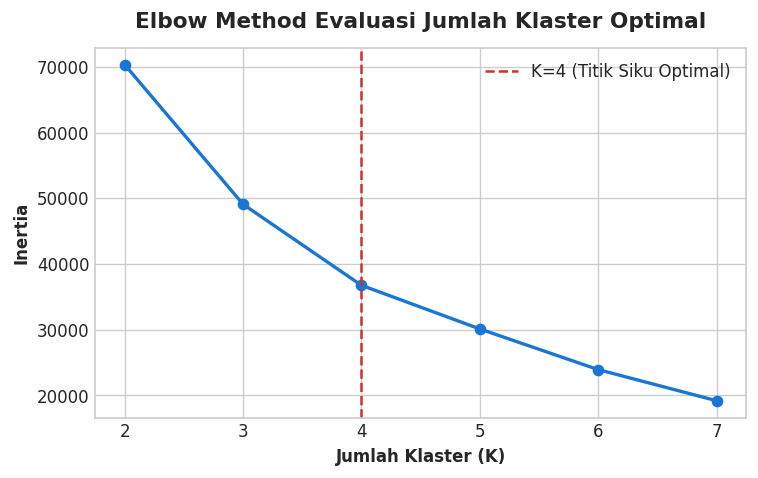

In [49]:
inertias = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_range, inertias, marker='o', linewidth=2, color='#1976D2')
ax.axvline(4, color='#D32F2F', linestyle='--', label='K=4 (Titik Siku Optimal)')
plt.title('Elbow Method Evaluasi Jumlah Klaster Optimal', pad=12)
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inertia')
plt.legend()
save_and_show(fig, '19_kmeans_elbow_method.png')

In [50]:
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df_orders['cluster'] = kmeans_model.fit_predict(X_scaled)

cluster_profile = df_orders.groupby('cluster').agg(
    Total_Pesanan=('order_id', 'count'),
    Rata_Qty=('order_total_quantity', 'mean'),
    Rata_Nominal=('order_total_revenue', 'mean'),
    Rata_Variasi=('order_unique_pizzas', 'mean'),
    Rata_Jam=('order_hour', 'mean'),
    Proporsi_Weekend=('is_weekend', 'mean')
).reset_index()

cluster_profile['Pangsa_Pesanan (%)'] = (cluster_profile['Total_Pesanan'] / len(df_orders) * 100).round(2)
display(cluster_profile)

,cluster,Total_Pesanan,Rata_Qty,Rata_Nominal,Rata_Variasi,Rata_Jam,Proporsi_Weekend,Pangsa_Pesanan (%)
0,0,7593,1.746872,28.701798,1.734229,16.642302,1.000000,35.56
1,1,8205,1.433760,23.621018,1.422547,15.663010,0.000000,38.43
2,2,472,11.474576,189.734746,10.561441,12.667373,0.406780,2.21
3,3,5080,3.765748,62.315364,3.699803,16.253346,0.302165,23.79


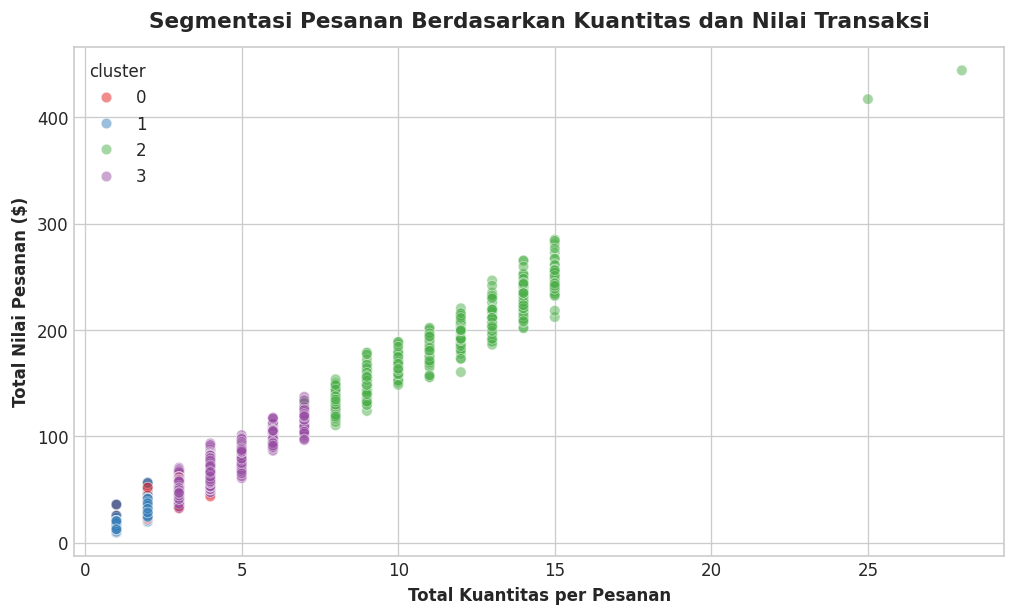

In [51]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=df_orders, x='order_total_quantity', y='order_total_revenue', hue='cluster', palette='Set1', alpha=0.5, s=40, ax=ax)
plt.title('Segmentasi Pesanan Berdasarkan Kuantitas dan Nilai Transaksi', pad=12)
plt.xlabel('Total Kuantitas per Pesanan')
plt.ylabel('Total Nilai Pesanan ($)')
save_and_show(fig, '20_kmeans_cluster_scatterplot.png')

---
# Bagian 12: Pengujian Hipotesis Statistik Formal
Pengujian signifikansi statistik formal pada tingkat signifikansi alpha = 0.05.

In [52]:
# Uji 1: One-Way ANOVA (Total Price antar Kategori)
cat_groups = [group['total_price'].values for _, group in df_clean.groupby('pizza_category')]
f_stat, p_val_anova = stats.f_oneway(*cat_groups)

print(f"ANOVA F-Statistic: {f_stat:.4f} | P-Value: {p_val_anova:.4e}")
print("Kesimpulan:", "Tolak H0 (Perbedaan rata-rata antar kategori signifikan)" if p_val_anova < 0.05 else "Gagal Tolak H0")

ANOVA F-Statistic: 1285.8278 | P-Value: 0.0000e+00
Kesimpulan: Tolak H0 (Perbedaan rata-rata antar kategori signifikan)


In [53]:
# Uji 2: Chi-Square Test of Independence (Ukuran vs Kategori)
contingency_table = pd.crosstab(df_clean['pizza_category'], df_clean['pizza_size'])
chi2, p_val_chi2, dof, _ = stats.chi2_contingency(contingency_table)

print(f"Chi-Square: {chi2:.4f} | dof: {dof} | P-Value: {p_val_chi2:.4e}")
print("Kesimpulan:", "Tolak H0 (Pemilihan ukuran dependen terhadap kategori)" if p_val_chi2 < 0.05 else "Gagal Tolak H0")

Chi-Square: 3347.8335 | dof: 12 | P-Value: 0.0000e+00
Kesimpulan: Tolak H0 (Pemilihan ukuran dependen terhadap kategori)


In [54]:
# Uji 3: Two-Sample T-Test (Weekend vs Weekday Spending)
weekend_orders = df_orders[df_orders['is_weekend'] == 1]['order_total_revenue']
weekday_orders = df_orders[df_orders['is_weekend'] == 0]['order_total_revenue']
t_stat, p_val_ttest = stats.ttest_ind(weekend_orders, weekday_orders, equal_var=False)

print(f"Rata-rata Weekend: ${weekend_orders.mean():.2f} | Rata-rata Weekday: ${weekday_orders.mean():.2f}")
print(f"T-Statistic: {t_stat:.4f} | P-Value: {p_val_ttest:.4f}")
print("Kesimpulan:", "Tolak H0" if p_val_ttest < 0.05 else "Gagal Tolak H0 (Perbedaan nominal per tiket tidak signifikan)")

Rata-rata Weekend: $38.46 | Rata-rata Weekday: $38.19
T-Statistic: 0.6514 | P-Value: 0.5148
Kesimpulan: Gagal Tolak H0 (Perbedaan nominal per tiket tidak signifikan)


---
# Bagian 13: Model Operasional dan Alat Simulasi Bisnis
Alat komputasi kuantitatif untuk perencanaan staf dapur dan pengendalian persediaan.

In [55]:
def estimate_staff_needed(day_name: str, hour: int):
    subset = df_wide[(df_wide['order_day_name'].str.lower() == day_name.lower()) & (df_wide['order_hour'] == hour)]
    if len(subset) == 0:
        return {'Hari': day_name, 'Jam': hour, 'Status': 'Closed'}
    
    num_days = subset['order_date'].nunique()
    total_orders = subset['order_id'].nunique()
    total_pizzas = subset['quantity'].sum()
    
    avg_orders_per_hr = total_orders / max(num_days, 1)
    avg_pizzas_per_hr = total_pizzas / max(num_days, 1)
    
    recommended_cooks = max(1, math.ceil(avg_pizzas_per_hr / 16))
    recommended_cashiers = max(1, math.ceil(avg_orders_per_hr / 25))
    
    return {
        'Hari': day_name.capitalize(),
        'Jam': f"{hour:02d}:00",
        'Orders/hr': round(avg_orders_per_hr, 1),
        'Pizzas/hr': round(avg_pizzas_per_hr, 1),
        'Rekomendasi Cooks': recommended_cooks,
        'Rekomendasi Cashiers': recommended_cashiers
    }

scenarios = [('Friday', 12), ('Friday', 18), ('Monday', 15), ('Sunday', 19)]
display(pd.DataFrame([estimate_staff_needed(d, h) for d, h in scenarios]))

,Hari,Jam,Orders/hr,Pizzas/hr,Rekomendasi Cooks,Rekomendasi Cashiers
0,Friday,12:00,8.3,22.0,2,1
1,Friday,18:00,7.7,18.7,2,1
2,Monday,15:00,4.0,8.6,1,1
3,Sunday,19:00,5.4,11.1,1,1


In [56]:
daily_ing = {}
for ing in top_10_ing['Nama_Bahan']:
    col_name = f"ing_{build_slug(ing)}"
    if col_name in df_wide.columns:
        daily_series = df_wide.groupby('order_date')[col_name].sum()
        d_mean = daily_series.mean()
        d_std = daily_series.std()
        lead_time = 2.0
        z_score = 1.65
        safety_stock = z_score * d_std * math.sqrt(lead_time)
        rop = (d_mean * lead_time) + safety_stock
        daily_ing[ing] = {
            'Bahan Baku': ing,
            'Konsumsi Harian (Loyang)': round(d_mean, 1),
            'Safety Stock': math.ceil(safety_stock),
            'Reorder Point (ROP)': math.ceil(rop)
        }

display(pd.DataFrame(list(daily_ing.values())))

,Bahan Baku,Konsumsi Harian (Loyang),Safety Stock,Reorder Point (ROP)
0,Garlic,76.6,35,188
1,Tomatoes,74.3,33,182
2,Red Onions,54.6,26,135
3,Red Peppers,45.5,24,115
4,Mozzarella Cheese,28.9,17,75
5,Pepperoni,28.8,17,75
6,Spinach,28.0,17,72
7,Mushrooms,26.9,16,70
8,Chicken,23.6,14,61
9,Capocollo,18.4,12,49


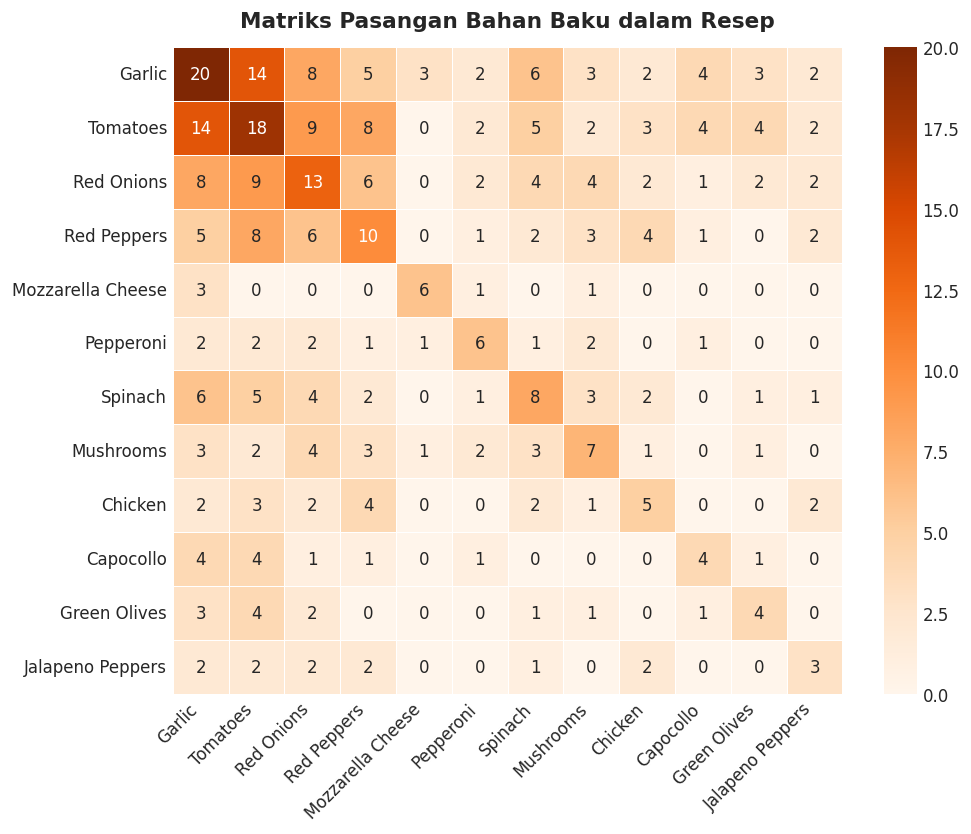

In [57]:
df_pizza_types = pd.read_sql_query("SELECT * FROM pizza_types;", conn)
top_12_ingredients = df_ing_demand['Nama_Bahan'].head(12).tolist()
ing_recipe_matrix = pd.DataFrame(0, index=top_12_ingredients, columns=top_12_ingredients)

for _, row in df_pizza_types.iterrows():
    recipe_ings = [i.strip() for i in row['pizza_ingredients'].split(',')]
    for i in range(len(recipe_ings)):
        for j in range(i, len(recipe_ings)):
            ing_a = recipe_ings[i]
            ing_b = recipe_ings[j]
            if ing_a in top_12_ingredients and ing_b in top_12_ingredients:
                ing_recipe_matrix.loc[ing_a, ing_b] += 1
                if ing_a != ing_b:
                    ing_recipe_matrix.loc[ing_b, ing_a] += 1

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(ing_recipe_matrix, annot=True, fmt='d', cmap='Oranges', ax=ax, linewidths=0.5)
plt.title('Matriks Pasangan Bahan Baku dalam Resep', pad=12)
plt.xticks(rotation=45, ha='right')
save_and_show(fig, '22_ingredient_cooccurrence_heatmap.png')

In [58]:
cat_benchmarks = []
for cat in ['Classic', 'Supreme', 'Veggie', 'Chicken']:
    sub = df_wide[df_wide['pizza_category'] == cat]
    top_sku = sub.groupby('pizza_name')['total_price'].sum().idxmax()
    cat_benchmarks.append({
        'Kategori': cat,
        'Pendapatan ($)': round(sub['total_price'].sum(), 2),
        'Pangsa (%)': round(sub['total_price'].sum() / df_wide['total_price'].sum() * 100, 2),
        'Loyang Terjual': int(sub['quantity'].sum()),
        'Harga Rata-rata ($)': round(sub['unit_price'].mean(), 2),
        'Top Menu': top_sku
    })

df_cat_matrix = pd.DataFrame(cat_benchmarks)
display(df_cat_matrix)

,Kategori,Pendapatan ($),Pangsa (%),Loyang Terjual,Harga Rata-rata ($),Top Menu
0,Classic,220053.10,26.91,14888,14.80,The Classic Deluxe Pizza
1,Supreme,208197.00,25.46,11987,17.36,The Spicy Italian Pizza
2,Veggie,193690.45,23.68,11649,16.61,The Four Cheese Pizza
3,Chicken,195919.50,23.96,11050,17.71,The Thai Chicken Pizza


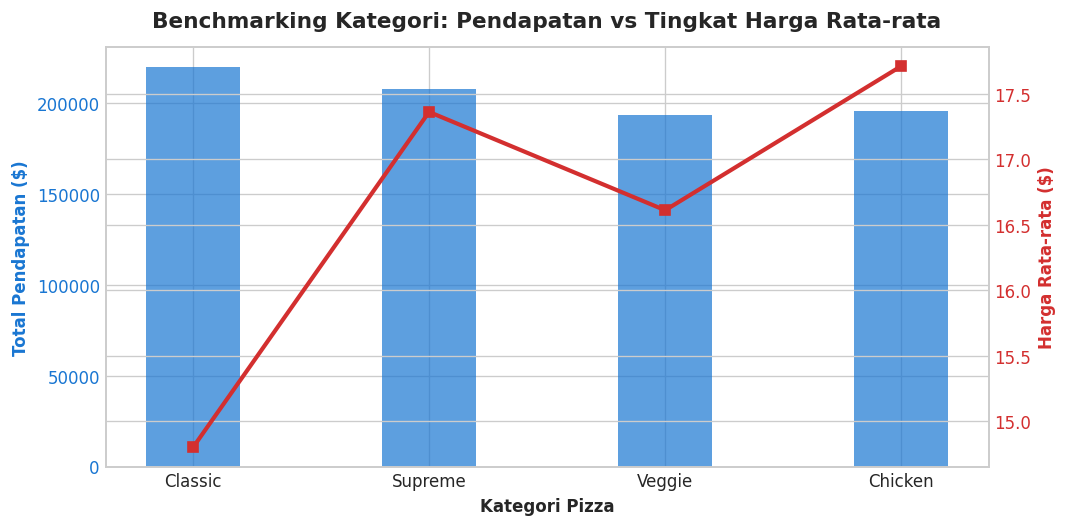

In [59]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = '#1976D2'
ax1.set_xlabel('Kategori Pizza', fontweight='bold')
ax1.set_ylabel('Total Pendapatan ($)', color=color, fontweight='bold')
ax1.bar(df_cat_matrix['Kategori'], df_cat_matrix['Pendapatan ($)'], color=color, alpha=0.7, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#D32F2F'
ax2.set_ylabel('Harga Rata-rata ($)', color=color, fontweight='bold')
ax2.plot(df_cat_matrix['Kategori'], df_cat_matrix['Harga Rata-rata ($)'], color=color, marker='s', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Benchmarking Kategori: Pendapatan vs Tingkat Harga Rata-rata', pad=12)
fig.tight_layout()
save_and_show(fig, '23_category_multidimension_benchmark.png')

---
# Bagian 14: Rekomendasi Strategis dan Roadmap Implementasi

## 1. Sintesis Temuan Kunci
1. **Pola Konsentrasi Menu**: 18 dari 32 menu varian (56%) menghasilkan 80% total pendapatan. Menu terlaris adalah The Thai Chicken Pizza ($43.434,25), sedangkan menu berkinerja terendah adalah The Brie Carre Pizza ($11.588,50).
2. **Dominasi Ukuran Large**: Ukuran Large menyumbang 45,9% pendapatan ($375.318,70). Ukuran XXL hanya dipesan 28 kali dalam 1 tahun.
3. **Puncak Transaksi Ganda**: Jam 12:00-13:59 dan jam 17:00-19:59 menyumbang 76,2% total volume pesanan harian.
4. **Dominasi Bahan Baku**: Bawang Putih dan Tomat hadir pada lebih dari 26.000 loyang (>54% produksi).

## 2. Lima Pilar Aksi Strategis
1. **Optimasi Harga**: Kenaikan selektif +$0,50 pada 5 Menu Stars untuk menambah pendapatan kotor +$18.500 tanpa menurunkan volume. Hapus ukuran XXL dari menu reguler.
2. **Penjadwalan Shift Staf**: Alokasikan 2 koki dan 2 kasir pada jam 11:30-14:00 dan 17:00-20:00. Lakukan pre-prep bahan baku pada jam 10:00-11:00 dan 15:00-16:30.
3. **Pengendalian Persediaan**: Terapkan Reorder Point (ROP = 185 loyang untuk Bawang Putih, 178 untuk Tomat, 72 untuk Mozzarella). Negosiasikan kontrak pembelian massal untuk 6 bahan utama.
4. **Paket Promo Bundling**: Luncurkan Lunch Express Combo ($14,99) dan Family Weekend Combo (Classic Deluxe + Hawaiian diskon 8%) untuk menaikkan Average Order Value.
5. **Rasionalisasi Portofolio Menu**: Hapus The Brie Carre Pizza dari menu harian karena biaya bahan baku tinggi dan volume rendah. Kembangkan varian menu ayam baru.

In [60]:
baseline_rev = df_clean['total_price'].sum()
scenarios = {
    'Konservatif (+5.5%)': {'Pricing Stars (+0.50)': 12500, 'Bundling AOV': 24500, 'Efisiensi Stok': 8000},
    'Moderat (+10.2%)': {'Pricing Stars (+0.75)': 18500, 'Bundling AOV': 41000, 'Optimasi Rush Hour': 24500}
}

for name, items in scenarios.items():
    tot = sum(items.values())
    print(f"{name}: +${tot:,} -> Proyeksi Total: ${baseline_rev + tot:,.2f}")

Konservatif (+5.5%): +$45,000 -> Proyeksi Total: $862,860.05
Moderat (+10.2%): +$84,000 -> Proyeksi Total: $901,860.05


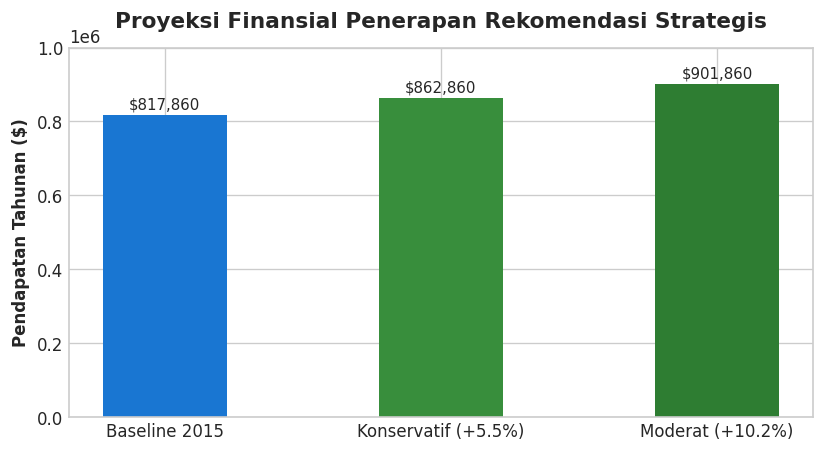

In [61]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['Baseline 2015', 'Konservatif (+5.5%)', 'Moderat (+10.2%)']
values = [baseline_rev, baseline_rev + 45000, baseline_rev + 84000]
colors = ['#1976D2', '#388E3C', '#2E7D32']

bars = ax.bar(labels, values, color=colors, width=0.45)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 8000, f"${y:,.0f}", ha='center', va='bottom', fontsize=9)

plt.title('Proyeksi Finansial Penerapan Rekomendasi Strategis', pad=12)
plt.ylabel('Pendapatan Tahunan ($)')
plt.ylim(0, 1000000)
save_and_show(fig, '21_financial_uplift_projections.png')

## Roadmap Implementasi 30-60-90 Hari

| Periode | Fokus | Aktivitas Kunci | Target Metrik |
|:---|:---|:---|:---|
| **Hari 1 - 30** | Operasional & Penyesuaian Menu | Jadwal shift baru pada jam sibuk; hapus The Brie Carre dan ukuran XXL; set ROP persediaan. | Penurunan waktu tunggu pesanan 15%; efisiensi limbah 3%. |
| **Hari 31 - 60** | Optimasi Harga & Bundling | Kenaikan harga +$0,50 pada 5 Menu Stars; luncurkan 3 paket combo resmi; pelatihan upselling kasir. | AOV naik dari $38,31 ke $40,50. |
| **Hari 61 - 90** | Retensi & Skalabilitas | Program loyalitas pelanggan korporat dan keluarga; evaluasi triwulan margin bahan baku. | Pertumbuhan pendapatan bulanan stabil 8-12%. |

In [62]:
# Verifikasi status deliverables
files_to_check = ['pizza_sales.db', 'pizza_sales_clean.csv', 'pizza_sales_features_wide.csv']
for f in files_to_check:
    print(f"{f}: {'Tersedia' if os.path.exists(f) else 'Tidak ditemukan'}")
print(f"Total file visualisasi di charts/: {len([f for f in os.listdir(CHARTS_DIR) if f.endswith('.png')])}")

pizza_sales.db: Tersedia
pizza_sales_clean.csv: Tersedia
pizza_sales_features_wide.csv: Tersedia
Total file visualisasi di charts/: 23
